### Section A: Data Authentication & Loading
We will authenticate your Google account to safely access the spreadsheet and load it into a pandas DataFrame.

In [1]:
from google.colab import auth
auth.authenticate_user()

import gspread
from google.auth import default
creds, _ = default()

gc = gspread.authorize(creds)

In [2]:
import pandas as pd

# Open the spreadsheet by URL
sheet_url = 'https://docs.google.com/spreadsheets/d/1iupjNMUEe_cHJdOhwBc-FkzDhvK09dHOm9cBtxi76-E/edit?gid=291095474#gid=291095474'
sheet = gc.open_by_url(sheet_url)

# Select the first worksheet
worksheet = sheet.get_worksheet(0)

# Get all values and convert to DataFrame
data = worksheet.get_all_values()
headers = data[0]
rows = data[1:]

df = pd.DataFrame(rows, columns=headers)

# Preview the dataset
display(df.head())

,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep,Total_Cost,Discount_Amount,Gross_Profit,Profit_Margin
0,1052,2023-02-03,Bob,North,"$5,053.97",18,Furniture,$152.75,$267.22,Returning,9.0%,Cash,Online,North-Bob,"$2,749.50",$454.86,"$2,304.47",45.6%
1,1093,2023-04-21,Bob,West,"$4,384.02",17,Furniture,"$3,816.39","$4,209.44",Returning,11.0%,Cash,Retail,West-Bob,"$64,878.63",$482.24,"-$60,494.61",-1379.9%
2,1015,2023-09-21,David,South,"$4,631.23",30,Food,$261.56,$371.40,Returning,20.0%,Bank Transfer,Retail,South-David,"$7,846.80",$926.25,"-$3,215.57",-69.4%
3,1072,2023-08-24,Bob,South,"$2,167.94",39,Clothing,"$4,330.03","$4,467.75",New,2.0%,Credit Card,Retail,South-Bob,"$168,871.17",$43.36,"-$166,703.23",-7689.5%
4,1061,2023-03-24,Charlie,East,"$3,750.20",13,Electronics,$637.37,$692.71,New,8.0%,Credit Card,Online,East-Charlie,"$8,285.81",$300.02,"-$4,535.61",-120.9%


### Section B: Initial Data Assessment & Validation
In this section, we will inspect the first and last records, identify columns and data types, verify the shape of the dataset, and check for missing, null, or duplicate values.

In [3]:
import pandas as pd

# 1. Load the CSV file using Pandas (Completed in previous cell as 'df')
# We will use the 'df' DataFrame obtained from the Google Sheet.

# 2. Display the first and last five records
print("--- First 5 Records ---")
display(df.head(5))
print("\n--- Last 5 Records ---")
display(df.tail(5))

--- First 5 Records ---


,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep,Total_Cost,Discount_Amount,Gross_Profit,Profit_Margin
0,1052,2023-02-03,Bob,North,"$5,053.97",18,Furniture,$152.75,$267.22,Returning,9.0%,Cash,Online,North-Bob,"$2,749.50",$454.86,"$2,304.47",45.6%
1,1093,2023-04-21,Bob,West,"$4,384.02",17,Furniture,"$3,816.39","$4,209.44",Returning,11.0%,Cash,Retail,West-Bob,"$64,878.63",$482.24,"-$60,494.61",-1379.9%
2,1015,2023-09-21,David,South,"$4,631.23",30,Food,$261.56,$371.40,Returning,20.0%,Bank Transfer,Retail,South-David,"$7,846.80",$926.25,"-$3,215.57",-69.4%
3,1072,2023-08-24,Bob,South,"$2,167.94",39,Clothing,"$4,330.03","$4,467.75",New,2.0%,Credit Card,Retail,South-Bob,"$168,871.17",$43.36,"-$166,703.23",-7689.5%
4,1061,2023-03-24,Charlie,East,"$3,750.20",13,Electronics,$637.37,$692.71,New,8.0%,Credit Card,Online,East-Charlie,"$8,285.81",$300.02,"-$4,535.61",-120.9%



--- Last 5 Records ---


,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep,Total_Cost,Discount_Amount,Gross_Profit,Profit_Margin
995,1010,2023-04-15,Charlie,North,"$4,733.88",4,Food,"$4,943.03","$5,442.15",Returning,29.0%,Cash,Online,North-Charlie,"$19,772.12","$1,372.83","-$15,038.24",-317.7%
996,1067,2023-09-07,Bob,North,"$4,716.36",37,Clothing,"$1,754.32","$1,856.40",New,21.0%,Bank Transfer,Retail,North-Bob,"$64,909.84",$990.44,"-$60,193.48",-1276.3%
997,1018,2023-04-27,David,South,"$7,629.70",17,Clothing,$355.72,$438.27,Returning,6.0%,Bank Transfer,Online,South-David,"$6,047.24",$457.78,"$1,582.46",20.7%
998,1100,2023-12-20,David,West,"$1,629.47",39,Electronics,"$3,685.03","$3,743.39",New,1.0%,Bank Transfer,Online,West-David,"$143,716.17",$16.29,"-$142,086.70",-8719.8%
999,1086,2023-08-16,Alice,East,"$4,923.93",48,Food,"$2,632.58","$2,926.68",Returning,14.0%,Cash,Online,East-Alice,"$126,363.84",$689.35,"-$121,439.91",-2466.3%


In [4]:
# 3. Find the number of rows and columns
print(f"\nShape of DataFrame: {df.shape[0]} rows, {df.shape[1]} columns")



Shape of DataFrame: 1000 rows, 18 columns


In [5]:
# 4. Check column names and data types
print("\n--- Column Information and Data Types ---")
print(df.info())


--- Column Information and Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Product_ID            1000 non-null   object
 1   Sale_Date             1000 non-null   object
 2   Sales_Rep             1000 non-null   object
 3   Region                1000 non-null   object
 4   Sales_Amount          1000 non-null   object
 5   Quantity_Sold         1000 non-null   object
 6   Product_Category      1000 non-null   object
 7   Unit_Cost             1000 non-null   object
 8   Unit_Price            1000 non-null   object
 9   Customer_Type         1000 non-null   object
 10  Discount              1000 non-null   object
 11  Payment_Method        1000 non-null   object
 12  Sales_Channel         1000 non-null   object
 13  Region_and_Sales_Rep  1000 non-null   object
 14  Total_Cost            1000 non-null   object
 

In [6]:
# 5. Identify missing or null values
print("\n--- Missing Values Per Column ---")
print(df.isnull().sum())


--- Missing Values Per Column ---
Product_ID              0
Sale_Date               0
Sales_Rep               0
Region                  0
Sales_Amount            0
Quantity_Sold           0
Product_Category        0
Unit_Cost               0
Unit_Price              0
Customer_Type           0
Discount                0
Payment_Method          0
Sales_Channel           0
Region_and_Sales_Rep    0
Total_Cost              0
Discount_Amount         0
Gross_Profit            0
Profit_Margin           0
dtype: int64


In [7]:
# 6. Detect duplicate records
duplicate_count = df.duplicated().sum()
print(f"\nNumber of duplicate records: {duplicate_count}")


Number of duplicate records: 0


In [8]:
# 7. Convert sale_date into a proper date format
if 'sale_date' in df.columns:
    df['sale_date'] = pd.to_datetime(df['sale_date'], errors='coerce')
    print("\n'sale_date' successfully converted to datetime.")

In [9]:
# 8. Check for invalid or negative values in key columns
numeric_cols = ['sales_amount', 'unit_cost', 'unit_price', 'Quantity_sold']
for col in numeric_cols:
    if col in df.columns:
        # Coerce to numeric first to perform numeric checks
        temp_series = pd.to_numeric(df[col], errors='coerce')
        negatives = (temp_series < 0).sum()
        print(f"Negative values in '{col}': {negatives}")

In [10]:
# 9. Check discount column format
if 'discount' in df.columns:
    print("\n--- Sample 'discount' values to check percentage vs decimal ---")
    print(df['discount'].unique()[:10])

In [11]:
# 10. Check unique values for standardization (category, region, payment-method)
standard_check_cols = ['category', 'region', 'payment-method', 'payment_method']
for col in standard_check_cols:
    if col in df.columns:
        print(f"\nUnique values in '{col}':")
        print(df[col].unique())

In [12]:
# Consolidated numpy import handled globally. Cell placeholder.

### Section C: Data Cleaning & Standardization
In this section, we standardize column names, correct formats, handle numeric types, check for anomalies, and clean inconsistent values to prepare our data for robust downstream analysis.

In [13]:
# 1. Standardize column names to make them easier to work with
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('-', '_')
print("Standardized Column Names:", df.columns.tolist())

Standardized Column Names: ['product_id', 'sale_date', 'sales_rep', 'region', 'sales_amount', 'quantity_sold', 'product_category', 'unit_cost', 'unit_price', 'customer_type', 'discount', 'payment_method', 'sales_channel', 'region_and_sales_rep', 'total_cost', 'discount_amount', 'gross_profit', 'profit_margin']


In [14]:
# 2. Convert 'sale_date' to datetime format
df['sale_date'] = pd.to_datetime(df['sale_date'], errors='coerce')
print("\nsale_date Data Type:", df['sale_date'].dtype)

# Helper function to clean numeric columns containing strings like '$', ',', '%'
def clean_numeric(val):
    if pd.isna(val):
        return np.nan
    if isinstance(val, (int, float)):
        return val
    val_str = str(val).strip().replace('$', '').replace(',', '').replace('%', '')
    return pd.to_numeric(val_str, errors='coerce')


sale_date Data Type: datetime64[ns]


In [15]:
# 3. Clean numeric columns
numeric_cols = ['sales_amount', 'unit_cost', 'unit_price', 'quantity_sold', 'discount']
for col in numeric_cols:
    if col in df.columns:
        df[col] = df[col].apply(clean_numeric)

In [16]:
# 4. Check for invalid or negative values in key columns
for col in ['sales_amount', 'unit_cost', 'unit_price', 'quantity_sold']:
    if col in df.columns:
        negatives = (df[col] < 0).sum()
        zeros = (df[col] == 0).sum()
        nans = df[col].isna().sum()
        print(f"\nChecking '{col}':")
        print(f"  - Negative values: {negatives}")
        print(f"  - Zero values: {zeros}")
        print(f"  - Missing/NaN values: {nans}")


Checking 'sales_amount':
  - Negative values: 0
  - Zero values: 0
  - Missing/NaN values: 0

Checking 'unit_cost':
  - Negative values: 0
  - Zero values: 0
  - Missing/NaN values: 0

Checking 'unit_price':
  - Negative values: 0
  - Zero values: 0
  - Missing/NaN values: 0

Checking 'quantity_sold':
  - Negative values: 0
  - Zero values: 0
  - Missing/NaN values: 0


In [17]:
# 5. Check discount column format
if 'discount' in df.columns:
    # Since we stripped '%', values like '9.0%' became 9.0. If they are percentages (> 1), we can inspect them.
    max_val = df['discount'].max()
    print(f"\nDiscount - Max Value: {max_val}, Min Value: {df['discount'].min()}")
    print("It appears the discount column is represented as percentages (e.g. 9.0 for 9%).")



Discount - Max Value: 30.0, Min Value: 0.0
It appears the discount column is represented as percentages (e.g. 9.0 for 9%).


In [18]:
# 6. Standardize inconsistent category, region, and payment-method names
for col in ['product_category', 'region', 'payment_method']:
    if col in df.columns:
        print(f"\nOriginal unique values in '{col}':", df[col].unique())
        # Standardizing casing and whitespace
        df[col] = df[col].astype(str).str.strip().str.title()
        print(f"Standardized unique values in '{col}':", df[col].unique())

# Display cleaned dataframe info and preview
print("\n--- Cleaned DataFrame Info ---")
display(df.info())
display(df.head())


Original unique values in 'product_category': ['Furniture' 'Food' 'Clothing' 'Electronics']
Standardized unique values in 'product_category': ['Furniture' 'Food' 'Clothing' 'Electronics']

Original unique values in 'region': ['North' 'West' 'South' 'East']
Standardized unique values in 'region': ['North' 'West' 'South' 'East']

Original unique values in 'payment_method': ['Cash' 'Bank Transfer' 'Credit Card']
Standardized unique values in 'payment_method': ['Cash' 'Bank Transfer' 'Credit Card']

--- Cleaned DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   product_id            1000 non-null   object        
 1   sale_date             1000 non-null   datetime64[ns]
 2   sales_rep             1000 non-null   object        
 3   region                1000 non-null   object        
 4   sales_am

None

,product_id,sale_date,sales_rep,region,sales_amount,quantity_sold,product_category,unit_cost,unit_price,customer_type,discount,payment_method,sales_channel,region_and_sales_rep,total_cost,discount_amount,gross_profit,profit_margin
0,1052,2023-02-03,Bob,North,5053.97,18,Furniture,152.75,267.22,Returning,9.0,Cash,Online,North-Bob,"$2,749.50",$454.86,"$2,304.47",45.6%
1,1093,2023-04-21,Bob,West,4384.02,17,Furniture,3816.39,4209.44,Returning,11.0,Cash,Retail,West-Bob,"$64,878.63",$482.24,"-$60,494.61",-1379.9%
2,1015,2023-09-21,David,South,4631.23,30,Food,261.56,371.40,Returning,20.0,Bank Transfer,Retail,South-David,"$7,846.80",$926.25,"-$3,215.57",-69.4%
3,1072,2023-08-24,Bob,South,2167.94,39,Clothing,4330.03,4467.75,New,2.0,Credit Card,Retail,South-Bob,"$168,871.17",$43.36,"-$166,703.23",-7689.5%
4,1061,2023-03-24,Charlie,East,3750.20,13,Electronics,637.37,692.71,New,8.0,Credit Card,Online,East-Charlie,"$8,285.81",$300.02,"-$4,535.61",-120.9%


### Section D: Exploratory Data Analysis (EDA)
Here, we compute key aggregate indicators, assess descriptive statistics, and plot distributions of sales and transaction quantities to get an initial look at our variables.

In [19]:
# Calculate and display EDA metrics
total_revenue = df['sales_amount'].sum()
total_quantity = df['quantity_sold'].sum()
avg_sales_per_trans = df['sales_amount'].mean()

unique_products = df['product_id'].nunique()
unique_reps = df['sales_rep'].nunique()
unique_regions = df['region'].nunique()
unique_categories = df['product_category'].nunique()

In [20]:
print("=== Exploratory Data Analysis (EDA) Summary ===")
print(f"Total Sales Revenue: ${total_revenue:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Average Sales Amount per Transaction: ${avg_sales_per_trans:,.2f}")
print(f"Number of Unique Products: {unique_products}")
print(f"Number of Sales Representatives: {unique_reps}")
print(f"Number of Regions: {unique_regions}")
print(f"Number of Product Categories: {unique_categories}")

print("\n=== Descriptive Statistics for Sales Amount and Quantities ===")
stats_df = df[['sales_amount', 'quantity_sold']].describe().T
# Add median to the stats table
stats_df.insert(5, 'median', df[['sales_amount', 'quantity_sold']].median())
display(stats_df)

=== Exploratory Data Analysis (EDA) Summary ===
Total Sales Revenue: $5,019,265.23
Total Quantity Sold: 25,355
Average Sales Amount per Transaction: $5,019.27
Number of Unique Products: 100
Number of Sales Representatives: 5
Number of Regions: 4
Number of Product Categories: 4

=== Descriptive Statistics for Sales Amount and Quantities ===


,count,mean,std,min,25%,median,50%,75%,max
sales_amount,1000.0,5019.26523,2846.790126,100.12,2550.2975,5019.3,5019.3,7507.445,9989.04
quantity_sold,1000.0,25.35500,14.159006,1.00,13.0000,25.0,25.0,38.000,49.00


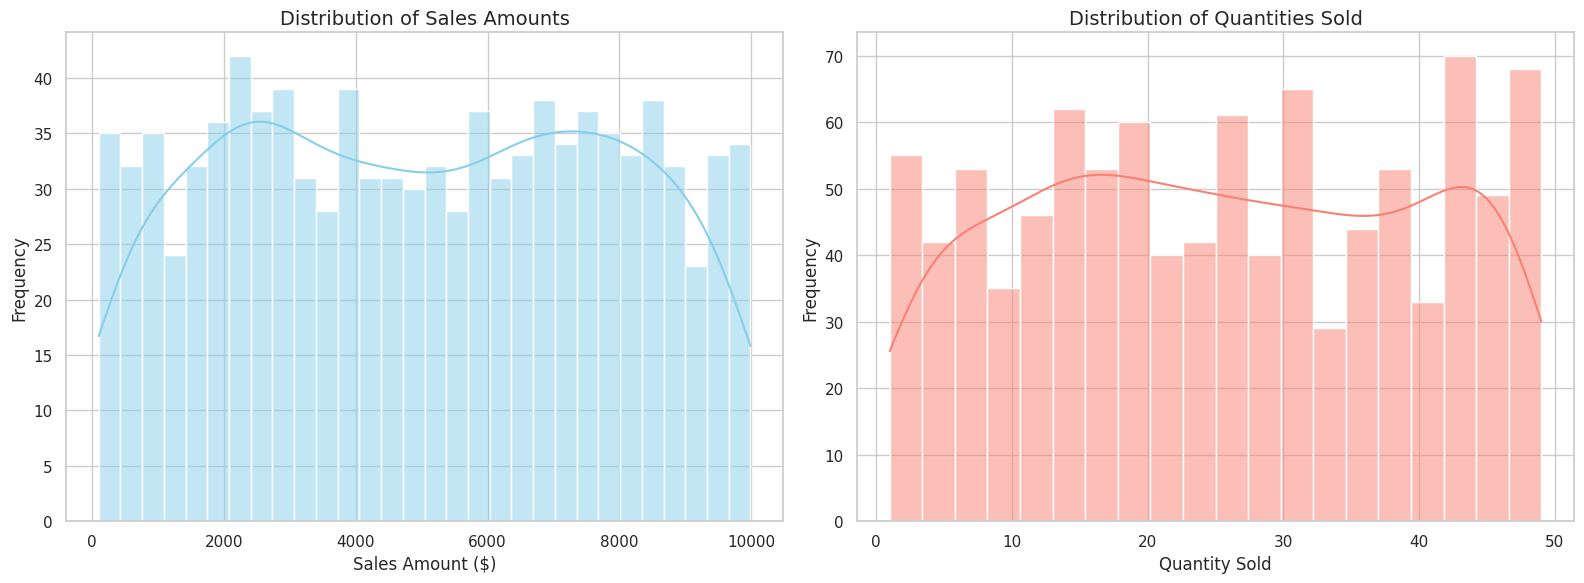

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the visualization style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot distribution of sales amounts
sns.histplot(df['sales_amount'], bins=30, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Sales Amounts', fontsize=14)
axes[0].set_xlabel('Sales Amount ($)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)

# Plot distribution of quantities sold
sns.histplot(df['quantity_sold'], bins=20, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Quantities Sold', fontsize=14)
axes[1].set_xlabel('Quantity Sold', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)

plt.tight_layout()
plt.show()

### Section E: Business & Profitability Metrics
We will define and calculate baseline profitability metrics, determine our most profitable items and categories, and identify discrepancies where sales volume does not translate into profit.

In [22]:
# 1. Compute foundational business metrics
# COGS = unit_cost * quantity_sold
df['calculated_cogs'] = df['unit_cost'] * df['quantity_sold']

# Profit = sales_amount - COGS
df['calculated_profit'] = df['sales_amount'] - df['calculated_cogs']

# Profit Margin = (Profit / Revenue) * 100
df['calculated_profit_margin'] = (df['calculated_profit'] / df['sales_amount']) * 100

# Display basic summary of our newly calculated columns
print("=== Calculated Profitability Metrics Summary ===")
display(df[['sales_amount', 'calculated_cogs', 'calculated_profit', 'calculated_profit_margin']].describe())


=== Calculated Profitability Metrics Summary ===


,sales_amount,calculated_cogs,calculated_profit,calculated_profit_margin
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,5019.265230,63842.093640,-58822.828410,-3116.804208
std,2846.790126,55398.598783,55549.189117,10246.118730
min,100.120000,60.280000,-235588.270000,-180829.714635
25%,2550.297500,18591.320000,-91927.975000,-2346.051726
50%,5019.300000,48453.135000,-43401.315000,-947.755156
75%,7507.445000,97755.397500,-14001.440000,-293.184742
max,9989.040000,235808.090000,8865.370000,99.083321


In [23]:
# 2. Which products generate the most profit?
print("\n=== Top 5 Most Profitable Products (By Total Profit) ===")
product_profit = df.groupby('product_id').agg(
    total_revenue=('sales_amount', 'sum'),
    total_profit=('calculated_profit', 'sum'),
    total_quantity=('quantity_sold', 'sum')
).sort_values(by='total_profit', ascending=False)
display(product_profit.head(5))


=== Top 5 Most Profitable Products (By Total Profit) ===


,total_revenue,total_profit,total_quantity
product_id,,,
1043,19475.57,-154359.67,65
1031,9782.28,-196321.98,64
1011,19099.43,-207960.78,75
1065,50350.08,-232256.14,105
1018,43906.17,-238172.02,160


In [24]:
# 3. Which categories have the highest profit margins?
print("\n=== Profit Margins by Product Category ===")
category_profit = df.groupby('product_category').agg(
    total_revenue=('sales_amount', 'sum'),
    total_profit=('calculated_profit', 'sum')
)
category_profit['category_margin_%'] = (category_profit['total_profit'] / category_profit['total_revenue']) * 100
display(category_profit.sort_values(by='category_margin_%', ascending=False))



=== Profit Margins by Product Category ===


,total_revenue,total_profit,category_margin_%
product_category,,,
Food,1201773.54,-12519004.06,-1041.710742
Electronics,1243499.64,-14753220.87,-1186.427434
Furniture,1260517.69,-15290301.71,-1213.017622
Clothing,1313474.36,-16260301.77,-1237.961110


In [25]:
# 4. Which products sell well (high quantity) but produce low profits?
print("\n=== High Volume (Top 25% by Quantity) but Low Profit Products ===")
q_limit = product_profit['total_quantity'].quantile(0.75)
high_volume_products = product_profit[product_profit['total_quantity'] >= q_limit]
display(high_volume_products.sort_values(by='total_profit', ascending=True).head(5))



=== High Volume (Top 25% by Quantity) but Low Profit Products ===


,total_revenue,total_profit,total_quantity
product_id,,,
1090,88043.25,-1557972.62,590
1092,90615.62,-1489514.78,548
1099,101773.87,-1412527.03,502
1089,82055.13,-1254831.18,390
1054,59543.86,-1121930.51,348


In [26]:
# 5. Which regions generate the most revenue and profit?
print("\n=== Revenue and Profit by Region ===")
region_profit = df.groupby('region').agg(
    total_revenue=('sales_amount', 'sum'),
    total_profit=('calculated_profit', 'sum')
)
region_profit['region_margin_%'] = (region_profit['total_profit'] / region_profit['total_revenue']) * 100
display(region_profit.sort_values(by='total_profit', ascending=False))



=== Revenue and Profit by Region ===


,total_revenue,total_profit,region_margin_%
region,,,
South,1154250.86,-13608579.40,-1178.996687
West,1235608.93,-14869867.95,-1203.444519
East,1259792.93,-15167050.92,-1203.932056
North,1369612.51,-15177330.14,-1108.147745


In [27]:
# 6. How do discounts affect profitability?
print("\n=== Impact of Discounts on Profitability (By Discount Bins) ===")
# Let's create discount bins
df['discount_bin'] = pd.cut(df['discount'], bins=[-1, 5, 10, 15, 20, 25, 100], labels=['0-5%', '5-10%', '10-15%', '15-20%', '20-25%', '25%+'])
discount_analysis = df.groupby('discount_bin', observed=False).agg(
    transaction_count=('sales_amount', 'count'),
    avg_sales_amount=('sales_amount', 'mean'),
    avg_profit=('calculated_profit', 'mean'),
    avg_profit_margin=('calculated_profit_margin', 'mean')
)
display(discount_analysis)


=== Impact of Discounts on Profitability (By Discount Bins) ===


,transaction_count,avg_sales_amount,avg_profit,avg_profit_margin
discount_bin,,,,
0-5%,180,5190.230778,-59185.802111,-2648.402492
5-10%,170,4693.052000,-64944.894412,-5514.700996
10-15%,152,4932.650724,-52839.162368,-2161.567943
15-20%,157,4999.943949,-58020.257325,-3154.293301
20-25%,193,5225.505026,-58556.584819,-2382.525570
25%+,148,5026.542365,-58693.229932,-2830.964727


In [28]:
print("=== 1. Top 5 Products by Total Revenue ===")
product_rank = df.groupby('product_id').agg(
    total_revenue=('sales_amount', 'sum'),
    total_quantity=('quantity_sold', 'sum'),
    total_profit=('calculated_profit', 'sum')
)
display(product_rank.sort_values(by='total_revenue', ascending=False).head(5))


=== 1. Top 5 Products by Total Revenue ===


,total_revenue,total_quantity,total_profit
product_id,,,
1099,101773.87,502,-1412527.03
1092,90615.62,548,-1489514.78
1033,89130.41,404,-811225.91
1090,88043.25,590,-1557972.62
1086,82269.71,357,-671784.35


In [29]:
print("\n=== 2. Top 5 Best-Selling Products by Quantity ===")
display(product_rank.sort_values(by='total_quantity', ascending=False).head(5))



=== 2. Top 5 Best-Selling Products by Quantity ===


,total_revenue,total_quantity,total_profit
product_id,,,
1090,88043.25,590,-1557972.62
1092,90615.62,548,-1489514.78
1062,76696.76,506,-1006258.73
1099,101773.87,502,-1412527.03
1058,63234.39,452,-1051592.50


In [30]:
print("\n=== 3. Top 5 Products with the Highest Profit ===")
# Note: From our previous step, many products are showing negative profits (losses). Let's see the top "least negative" or highest profit ones.
display(product_rank.sort_values(by='total_profit', ascending=False).head(5))



=== 3. Top 5 Products with the Highest Profit ===


,total_revenue,total_quantity,total_profit
product_id,,,
1043,19475.57,65,-154359.67
1031,9782.28,64,-196321.98
1011,19099.43,75,-207960.78
1065,50350.08,105,-232256.14
1018,43906.17,160,-238172.02


In [31]:
print("\n=== 4. Revenue and Average Selling Price (Unit Price) across Product Categories ===")
category_perf = df.groupby('product_category').agg(
    total_revenue=('sales_amount', 'sum'),
    avg_unit_price=('unit_price', 'mean'),
    total_profit=('calculated_profit', 'sum')
)
display(category_perf.sort_values(by='total_revenue', ascending=False))



=== 4. Revenue and Average Selling Price (Unit Price) across Product Categories ===


,total_revenue,avg_unit_price,total_profit
product_category,,,
Clothing,1313474.36,2721.256381,-16260301.77
Furniture,1260517.69,2734.065346,-15290301.71
Electronics,1243499.64,2795.207195,-14753220.87
Food,1201773.54,2657.811726,-12519004.06


In [32]:
print("\n=== 5. Bottom 5 Low-Performing Products by Total Revenue ===")
display(product_rank.sort_values(by='total_revenue', ascending=True).head(5))



=== 5. Bottom 5 Low-Performing Products by Total Revenue ===


,total_revenue,total_quantity,total_profit
product_id,,,
1083,8059.05,125,-279084.40
1031,9782.28,64,-196321.98
1041,10682.46,151,-238952.94
1079,17828.37,186,-264203.64
1011,19099.43,75,-207960.78


In [33]:
print("\n=== 6. Products that Sell in High Volumes but have Low/Negative Profit Margins ===")
# Let's filter products with volume in the top 25% but profit margins below 0%
product_rank['profit_margin_%'] = (product_rank['total_profit'] / product_rank['total_revenue']) * 100
q_high = product_rank['total_quantity'].quantile(0.75)
high_vol_low_margin = product_rank[(product_rank['total_quantity'] >= q_high) & (product_rank['profit_margin_%'] < 0)]
display(high_vol_low_margin.sort_values(by='profit_margin_%', ascending=True).head(5))


=== 6. Products that Sell in High Volumes but have Low/Negative Profit Margins ===


,total_revenue,total_quantity,total_profit,profit_margin_%
product_id,,,,
1054,59543.86,348,-1121930.51,-1884.208565
1090,88043.25,590,-1557972.62,-1769.553736
1067,44611.00,333,-742371.43,-1664.099505
1058,63234.39,452,-1051592.50,-1663.007266
1092,90615.62,548,-1489514.78,-1643.772652


### Section F: Regional Sales Performance
We will investigate regional performance based on revenue, profitability, units sold, and the performance of product categories and sales representatives within each region.

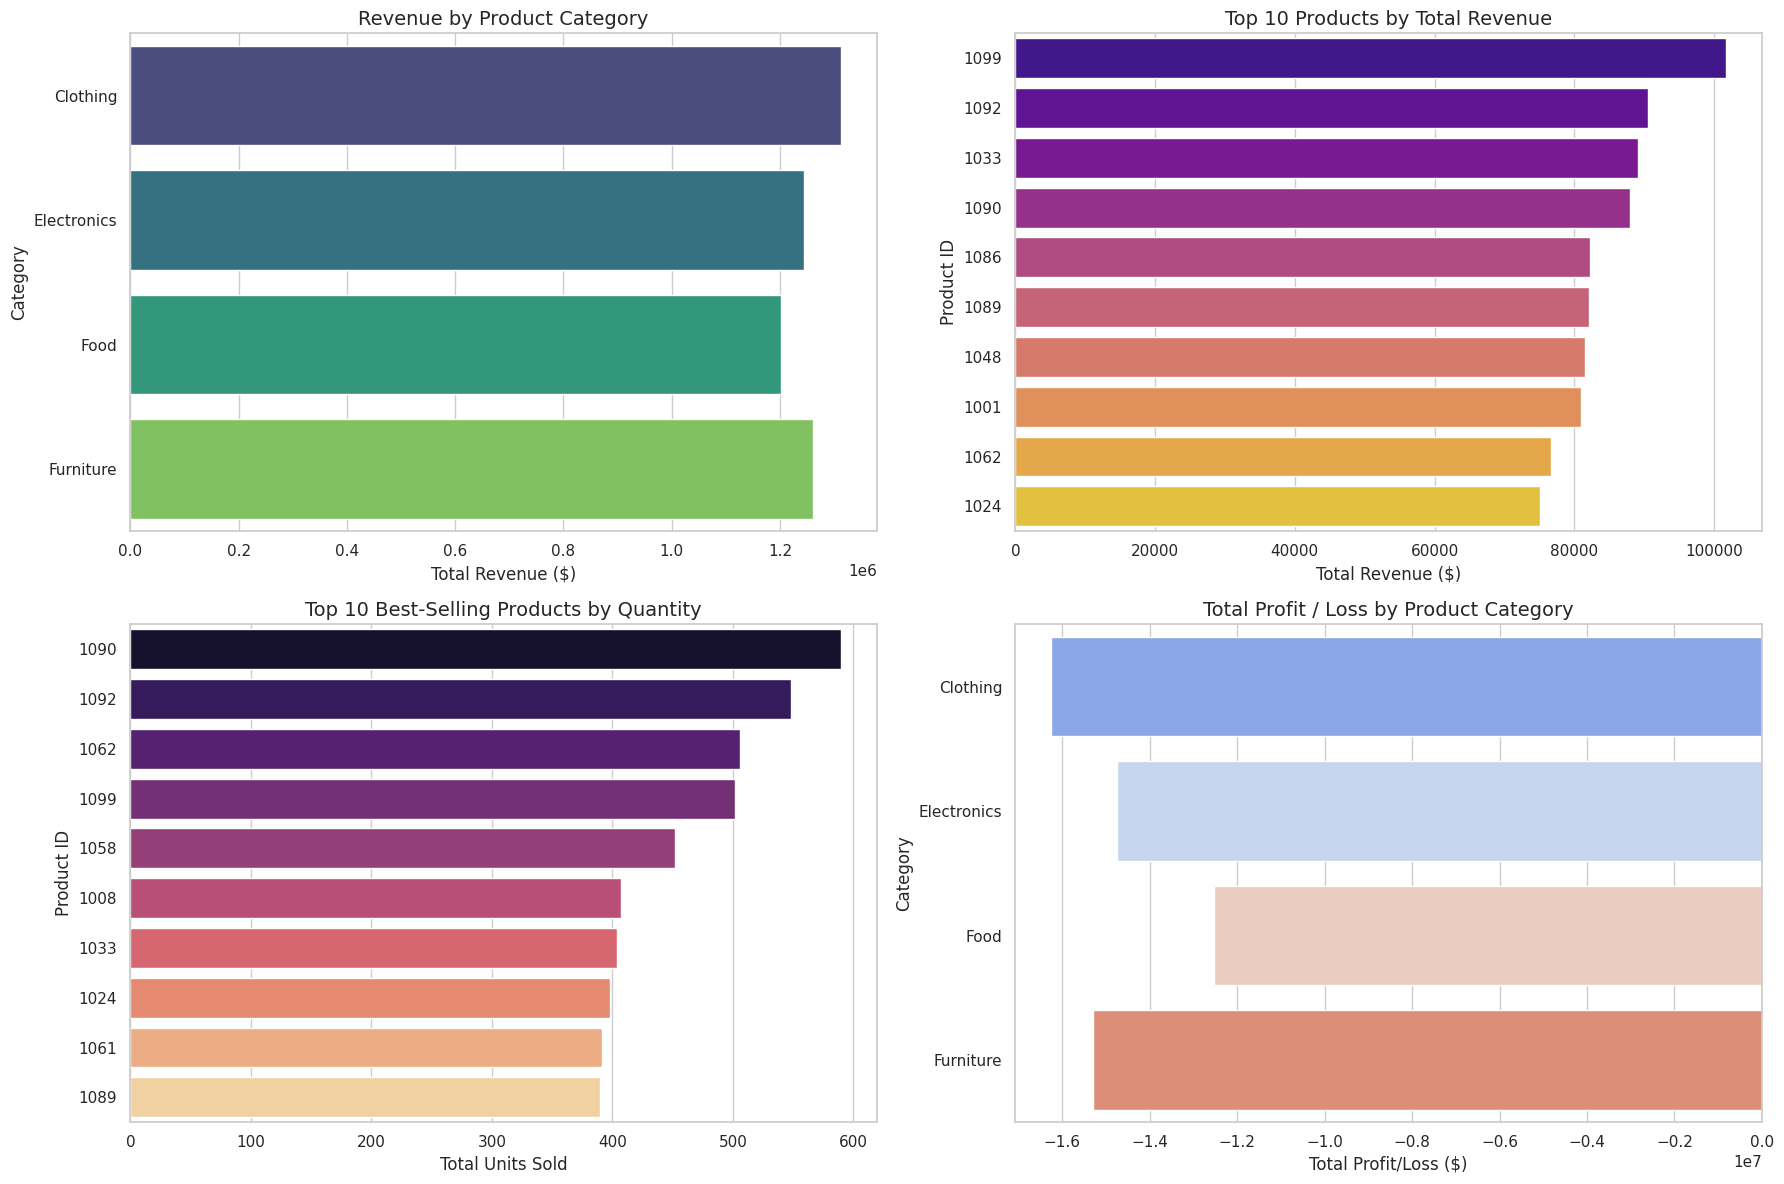

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Compare revenue across product categories (Bar Chart / Pie Chart)
category_revenue = df.groupby('product_category')['sales_amount'].sum().reset_index()
sns.barplot(x='sales_amount', y='product_category', data=category_revenue, ax=axes[0, 0], palette='viridis', hue='product_category', legend=False)
axes[0, 0].set_title('Revenue by Product Category', fontsize=14)
axes[0, 0].set_xlabel('Total Revenue ($)', fontsize=12)
axes[0, 0].set_ylabel('Category', fontsize=12)

# 2. Rank products by total revenue (Horizontal Ranking of Top 10)
top_10_products = product_rank.sort_values(by='total_revenue', ascending=False).head(10).reset_index()
sns.barplot(x='total_revenue', y=top_10_products['product_id'].astype(str), data=top_10_products, ax=axes[0, 1], palette='plasma', hue=top_10_products['product_id'].astype(str), legend=False)
axes[0, 1].set_title('Top 10 Products by Total Revenue', fontsize=14)
axes[0, 1].set_xlabel('Total Revenue ($)', fontsize=12)
axes[0, 1].set_ylabel('Product ID', fontsize=12)

# 3. Best-selling products by quantity (Horizontal Ranking of Top 10)
top_10_qty = product_rank.sort_values(by='total_quantity', ascending=False).head(10).reset_index()
sns.barplot(x='total_quantity', y=top_10_qty['product_id'].astype(str), data=top_10_qty, ax=axes[1, 0], palette='magma', hue=top_10_qty['product_id'].astype(str), legend=False)
axes[1, 0].set_title('Top 10 Best-Selling Products by Quantity', fontsize=14)
axes[1, 0].set_xlabel('Total Units Sold', fontsize=12)
axes[1, 0].set_ylabel('Product ID', fontsize=12)

# 4. Profitability comparison per category
category_perf_reset = category_perf.reset_index()
sns.barplot(x='total_profit', y='product_category', data=category_perf_reset, ax=axes[1, 1], palette='coolwarm', hue='product_category', legend=False)
axes[1, 1].set_title('Total Profit / Loss by Product Category', fontsize=14)
axes[1, 1].set_xlabel('Total Profit/Loss ($)', fontsize=12)
axes[1, 1].set_ylabel('Category', fontsize=12)

plt.tight_layout()
plt.show()

In [35]:
# 1. Aggregate core metrics by Region
region_summary = df.groupby('region').agg(
    total_revenue=('sales_amount', 'sum'),
    total_quantity_sold=('quantity_sold', 'sum'),
    total_profit=('calculated_profit', 'sum'),
    average_transaction_value=('sales_amount', 'mean')
).reset_index()

# Calculate profit margin % per region
region_summary['profit_margin_%'] = (region_summary['total_profit'] / region_summary['total_revenue']) * 100

print("=== Overall Performance by Region ===")
display(region_summary.sort_values(by='total_revenue', ascending=False))

=== Overall Performance by Region ===


,region,total_revenue,total_quantity_sold,total_profit,average_transaction_value,profit_margin_%
1,North,1369612.51,6705,-15177330.14,5129.634869,-1108.147745
0,East,1259792.93,6356,-15167050.92,4790.087186,-1203.932056
3,West,1235608.93,6486,-14869867.95,5063.971025,-1203.444519
2,South,1154250.86,5808,-13608579.40,5107.304690,-1178.996687


In [36]:
# 2. Analyze which categories perform best in each region
region_category = df.groupby(['region', 'product_category']).agg(
    total_revenue=('sales_amount', 'sum'),
    total_quantity_sold=('quantity_sold', 'sum'),
    total_profit=('calculated_profit', 'sum')
).reset_index()

# Identify best performing categories by revenue in each region
print("=== Category Performance within Each Region ===")
display(region_category.sort_values(by=['region', 'total_revenue'], ascending=[True, False]))

=== Category Performance within Each Region ===


,region,product_category,total_revenue,total_quantity_sold,total_profit
0,East,Clothing,356670.40,1797,-4154404.57
2,East,Food,325864.87,1463,-3294797.68
1,East,Electronics,303101.42,1623,-4254621.37
3,East,Furniture,274156.24,1473,-3463227.30
7,North,Furniture,394983.35,1927,-4081531.59
4,North,Clothing,372977.22,1939,-4338907.12
5,North,Electronics,342666.29,1660,-3609262.53
6,North,Food,258985.65,1179,-3147628.90
10,South,Food,301187.51,1577,-3235142.12
9,South,Electronics,293663.96,1274,-3060963.95


In [37]:
# 3. Analyze sales representative performance within each region
region_rep = df.groupby(['region', 'sales_rep']).agg(
    total_revenue=('sales_amount', 'sum'),
    total_quantity_sold=('quantity_sold', 'sum'),
    total_profit=('calculated_profit', 'sum')
).reset_index()

print("=== Sales Representative Performance within Each Region ===")
display(region_rep.sort_values(by=['region', 'total_revenue'], ascending=[True, False]))

=== Sales Representative Performance within Each Region ===


,region,sales_rep,total_revenue,total_quantity_sold,total_profit
1,East,Bob,309876.11,1317,-3118548.80
3,East,David,284613.51,1454,-3453641.18
0,East,Alice,260789.47,1318,-3223422.00
4,East,Eve,239340.90,1273,-3029313.13
2,East,Charlie,165172.94,994,-2342125.81
9,North,Eve,304172.20,1527,-3218719.87
7,North,Charlie,299789.01,1184,-2347556.40
8,North,David,282539.27,1630,-4215675.59
5,North,Alice,249647.22,1221,-2611001.66
6,North,Bob,233464.81,1143,-2784376.62


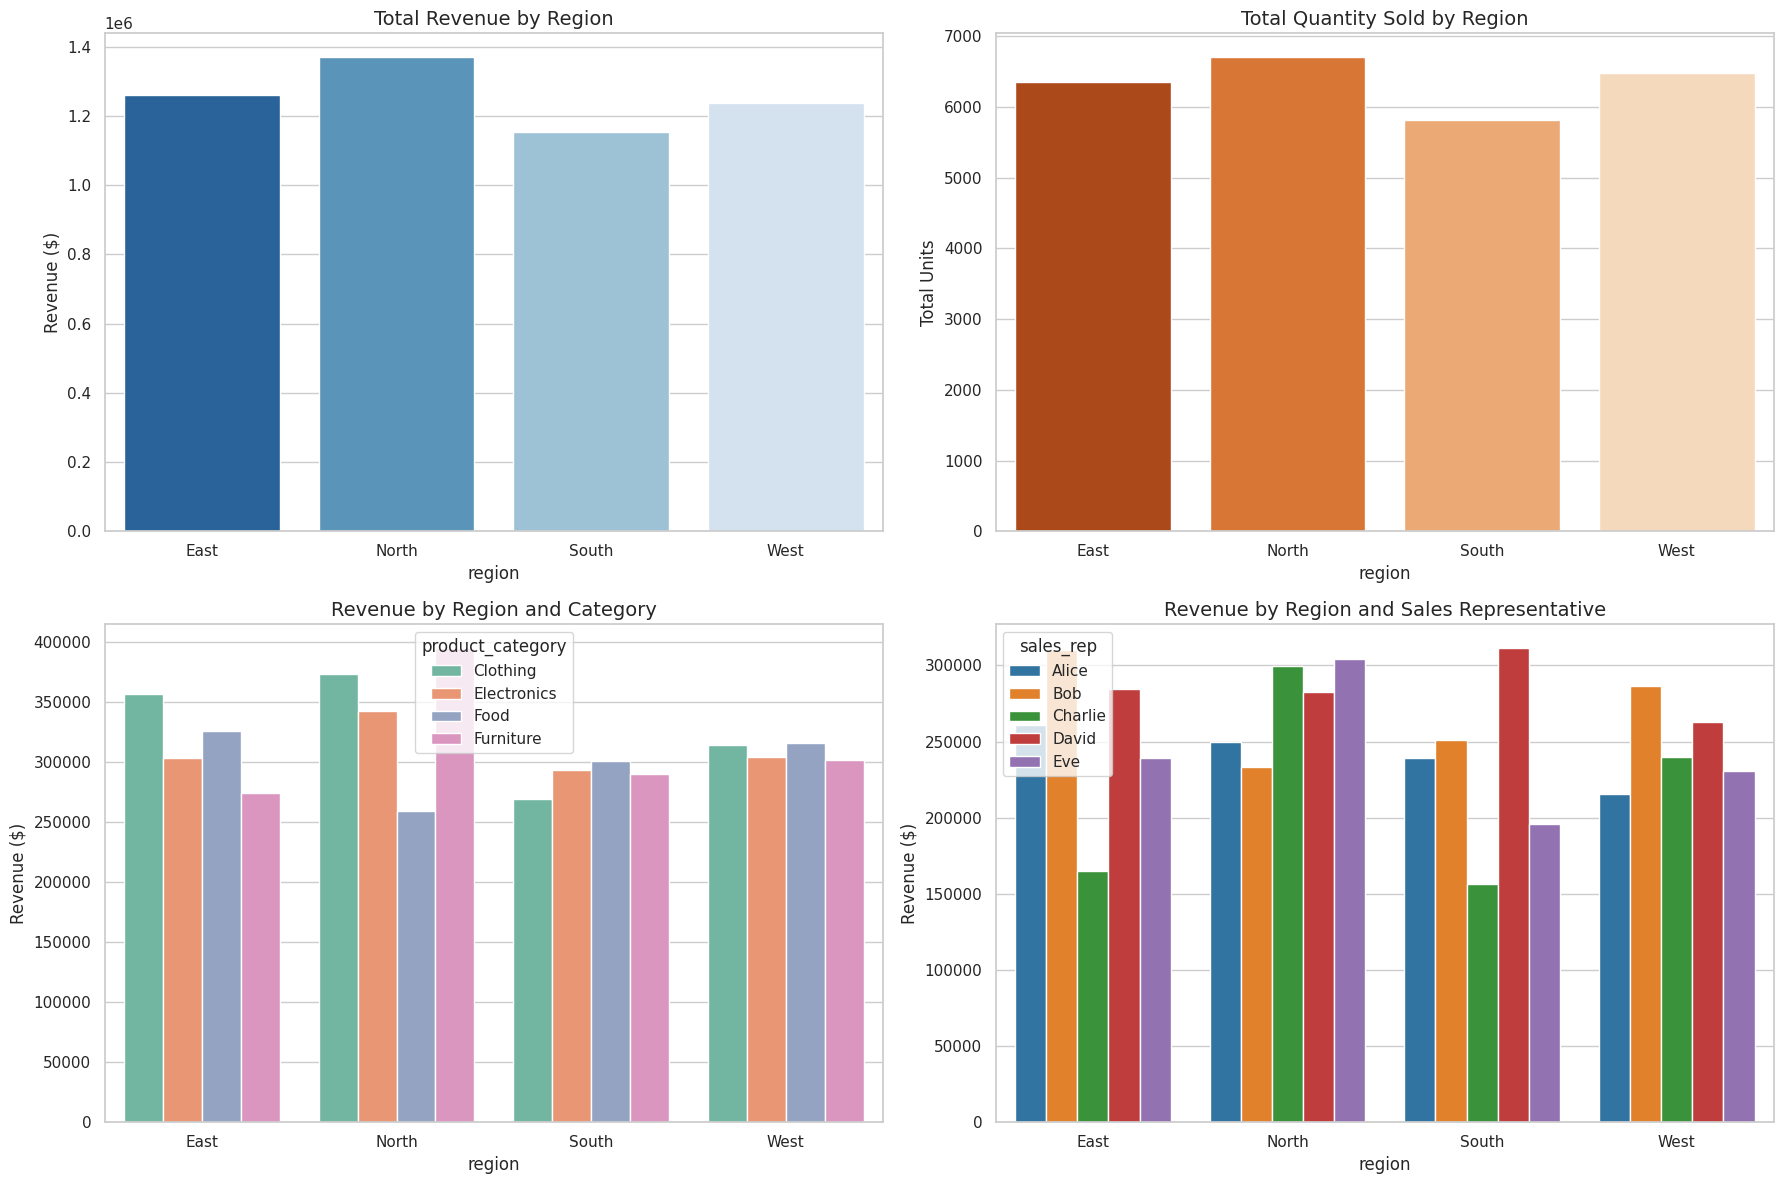

In [38]:
# 4. Visualize Regional Performance Metrics
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Subplot 1: Total Revenue by Region
sns.barplot(x='region', y='total_revenue', data=region_summary, ax=axes[0,0], palette='Blues_r', hue='region', legend=False)
axes[0,0].set_title('Total Revenue by Region', fontsize=14)
axes[0,0].set_ylabel('Revenue ($)', fontsize=12)

# Subplot 2: Total Units Sold by Region
sns.barplot(x='region', y='total_quantity_sold', data=region_summary, ax=axes[0,1], palette='Oranges_r', hue='region', legend=False)
axes[0,1].set_title('Total Quantity Sold by Region', fontsize=14)
axes[0,1].set_ylabel('Total Units', fontsize=12)

# Subplot 3: Revenue Distribution by Region & Category
sns.barplot(x='region', y='total_revenue', hue='product_category', data=region_category, ax=axes[1,0], palette='Set2')
axes[1,0].set_title('Revenue by Region and Category', fontsize=14)
axes[1,0].set_ylabel('Revenue ($)', fontsize=12)

# Subplot 4: Profitability by Representative within each Region
sns.barplot(x='region', y='total_revenue', hue='sales_rep', data=region_rep, ax=axes[1,1], palette='tab10')
axes[1,1].set_title('Revenue by Region and Sales Representative', fontsize=14)
axes[1,1].set_ylabel('Revenue ($)', fontsize=12)

plt.tight_layout()
plt.show()

### Section G: Temporal & Advanced Time-Series Trends
In this section, we analyze monthly sales patterns, transaction counts, rolling trends, and profit variations over time to identify seasonal spikes or declines.

In [39]:
# Extract month and year-month for grouping
df['year_month'] = df['sale_date'].dt.to_period('M')

# Aggregate metrics by Year-Month
temporal_summary = df.groupby('year_month').agg(
    total_revenue=('sales_amount', 'sum'),
    total_quantity_sold=('quantity_sold', 'sum'),
    total_profit=('calculated_profit', 'sum'),
    transaction_count=('sales_amount', 'count')
).reset_index()

temporal_summary['year_month'] = temporal_summary['year_month'].astype(str)

print("=== Monthly Sales and Profit Trend Summary ===")
display(temporal_summary.sort_values(by='year_month'))

=== Monthly Sales and Profit Trend Summary ===


,year_month,total_revenue,total_quantity_sold,total_profit,transaction_count
0,2023-01,476092.36,2472,-6296526.10,100
1,2023-02,368919.36,2064,-4780505.01,75
2,2023-03,402638.77,2069,-5076988.83,80
3,2023-04,438992.61,1977,-4533498.19,81
4,2023-05,389078.76,1968,-4922075.60,72
5,2023-06,418458.34,2276,-5118110.69,92
6,2023-07,374242.88,1603,-3929510.78,68
7,2023-08,443171.28,2336,-5714601.64,93
8,2023-09,367837.60,1815,-3716237.46,68
9,2023-10,460378.78,2386,-5515547.78,88


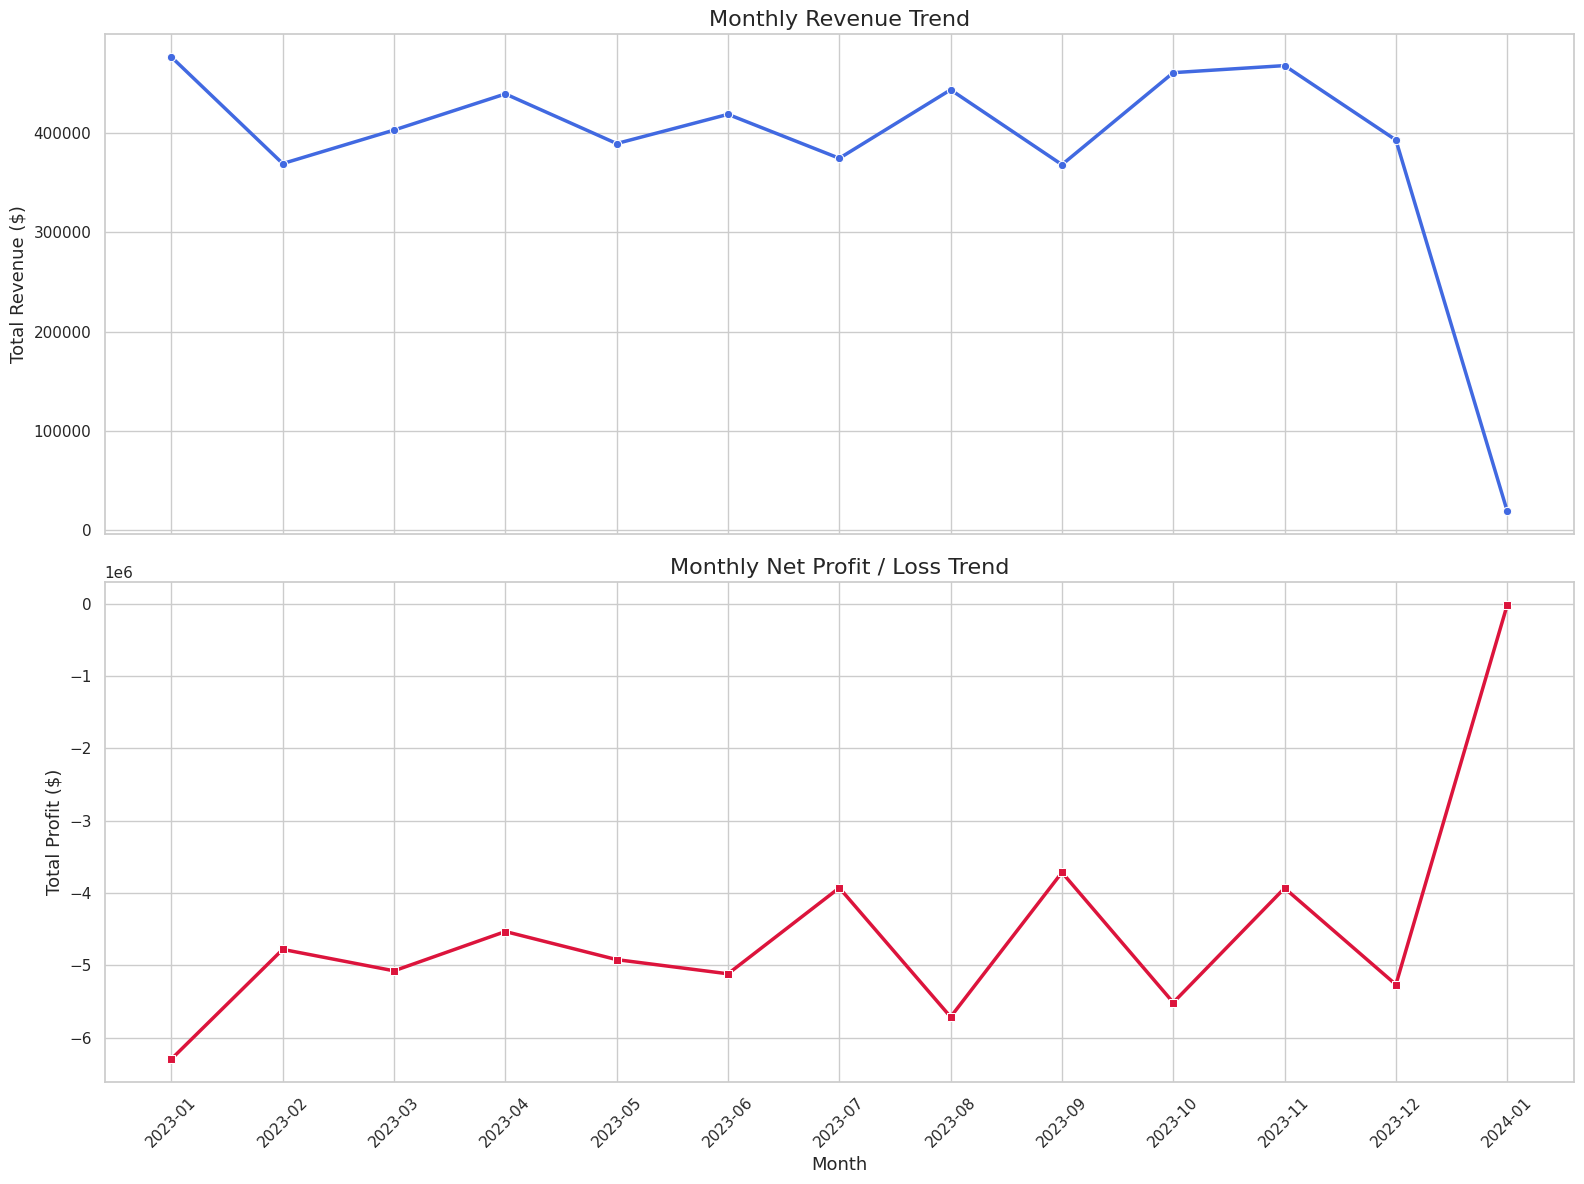

In [40]:
# Visualize monthly sales and profit trends
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)

# Top Plot: Monthly Sales Revenue
sns.lineplot(x='year_month', y='total_revenue', data=temporal_summary, marker='o', color='royalblue', linewidth=2.5, ax=axes[0])
axes[0].set_title('Monthly Revenue Trend', fontsize=16)
axes[0].set_ylabel('Total Revenue ($)', fontsize=13)
axes[0].tick_params(axis='x', rotation=45)

# Bottom Plot: Monthly Total Profit
sns.lineplot(x='year_month', y='total_profit', data=temporal_summary, marker='s', color='crimson', linewidth=2.5, ax=axes[1])
axes[1].set_title('Monthly Net Profit / Loss Trend', fontsize=16)
axes[1].set_xlabel('Month', fontsize=13)
axes[1].set_ylabel('Total Profit ($)', fontsize=13)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Section H: Sales Representative Performance
In this section, we analyze individual sales representative performance to measure total sales, volume, profitability, average transaction value, and regional contributions.

In [41]:
# 1. Overall Sales Representative Performance Summary
rep_summary = df.groupby('sales_rep').agg(
    total_revenue=('sales_amount', 'sum'),
    total_quantity_sold=('quantity_sold', 'sum'),
    average_sales_value=('sales_amount', 'mean'),
    total_profit=('calculated_profit', 'sum'),
    transaction_count=('sales_amount', 'count')
).reset_index()

# Calculate overall profit margin % per rep
rep_summary['profit_margin_%'] = (rep_summary['total_profit'] / rep_summary['total_revenue']) * 100

# Calculate contribution as a percentage of total company revenue
total_company_revenue = df['sales_amount'].sum()
rep_summary['revenue_contribution_%'] = (rep_summary['total_revenue'] / total_company_revenue) * 100

print("=== Sales Representative Performance Ranking ===")
display(rep_summary.sort_values(by='total_revenue', ascending=False))

=== Sales Representative Performance Ranking ===


,sales_rep,total_revenue,total_quantity_sold,average_sales_value,total_profit,transaction_count,profit_margin_%,revenue_contribution_%
3,David,1141737.36,6042,5142.961081,-13752096.83,222,-1204.488643,22.747102
1,Bob,1080990.63,4977,5197.070337,-11460837.31,208,-1060.216157,21.536830
4,Eve,970183.99,5287,4642.028660,-12852483.55,209,-1324.747026,19.329203
0,Alice,965541.77,4832,5028.863385,-11137366.31,192,-1153.483635,19.236715
2,Charlie,860811.48,4217,5093.559053,-9620044.41,169,-1117.555311,17.150149


In [42]:
# 2. Identify the best-performing representative in each region
best_rep_per_region = region_rep.sort_values(by=['region', 'total_revenue'], ascending=[True, False]).groupby('region').first().reset_index()

print("=== Top Representative in Each Region ===")
display(best_rep_per_region)

=== Top Representative in Each Region ===


,region,sales_rep,total_revenue,total_quantity_sold,total_profit
0,East,Bob,309876.11,1317,-3118548.80
1,North,Eve,304172.20,1527,-3218719.87
2,South,David,311416.99,1499,-2808335.91
3,West,Bob,286449.28,1545,-3267027.14


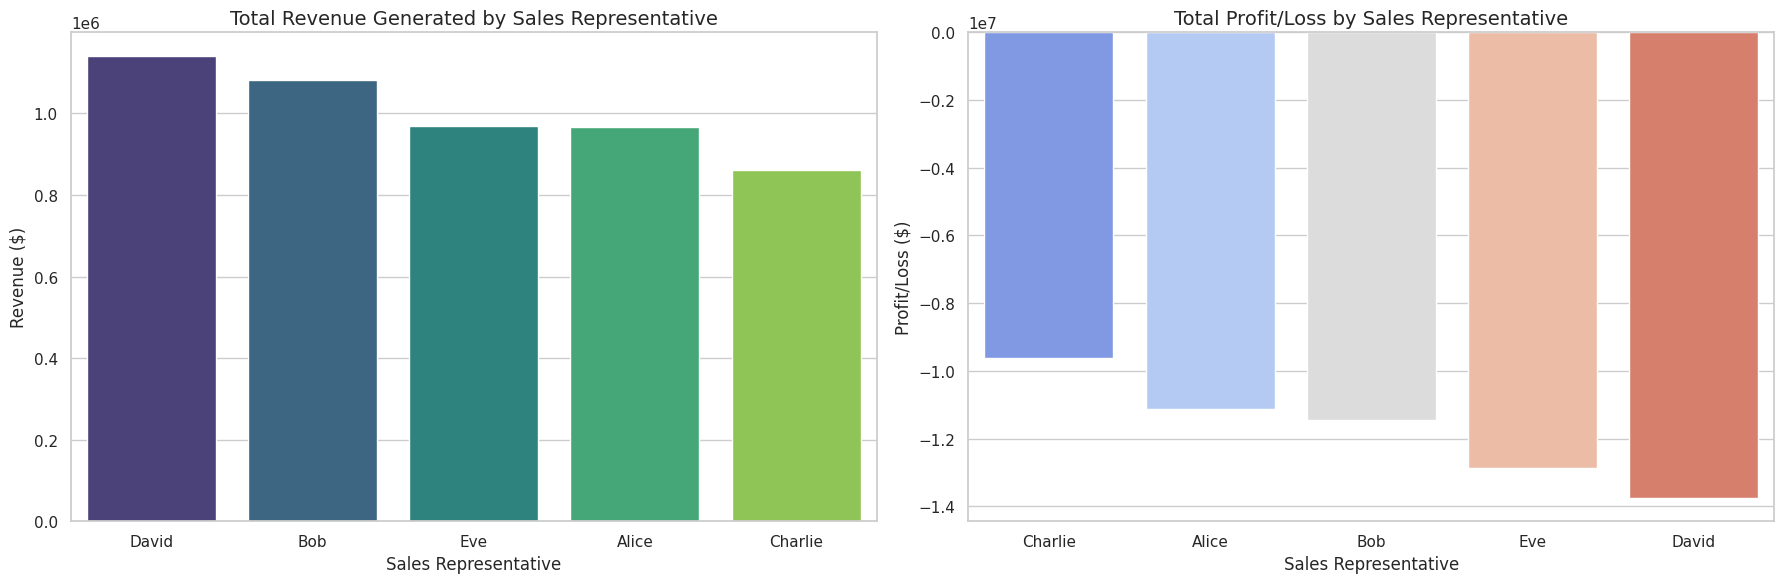

In [43]:
# 3. Visualize Sales Representative Metrics
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Total Revenue and Contribution % by Representative
sns.barplot(x='sales_rep', y='total_revenue', data=rep_summary.sort_values(by='total_revenue', ascending=False), ax=axes[0], palette='viridis', hue='sales_rep', legend=False)
axes[0].set_title('Total Revenue Generated by Sales Representative', fontsize=14)
axes[0].set_ylabel('Revenue ($)', fontsize=12)
axes[0].set_xlabel('Sales Representative', fontsize=12)

# Plot 2: Total Net Profit/Loss by Representative
sns.barplot(x='sales_rep', y='total_profit', data=rep_summary.sort_values(by='total_profit', ascending=False), ax=axes[1], palette='coolwarm', hue='sales_rep', legend=False)
axes[1].set_title('Total Profit/Loss by Sales Representative', fontsize=14)
axes[1].set_ylabel('Profit/Loss ($)', fontsize=12)
axes[1].set_xlabel('Sales Representative', fontsize=12)

plt.tight_layout()
plt.show()

In [44]:
# 1. Prepare additional time metrics
df['day_name'] = df['sale_date'].dt.day_name()
df['is_weekend'] = df['sale_date'].dt.dayofweek.isin([5, 6])
df['quarter'] = df['sale_date'].dt.to_period('Q').astype(str)

# 2. Daily Sales and 7-day Rolling Average
daily_sales = df.groupby('sale_date').agg(daily_revenue=('sales_amount', 'sum')).reset_index()
daily_sales = daily_sales.sort_values(by='sale_date')
daily_sales['rolling_7_day_rev'] = daily_sales['daily_revenue'].rolling(window=7, min_periods=1).mean()

print("=== Sample of Daily Revenue with 7-Day Rolling Average ===")
display(daily_sales.head(10))

=== Sample of Daily Revenue with 7-Day Rolling Average ===


,sale_date,daily_revenue,rolling_7_day_rev
0,2023-01-01,14141.12,14141.120000
1,2023-01-02,6452.79,10296.955000
2,2023-01-03,21319.08,13970.996667
3,2023-01-04,30175.06,18022.012500
4,2023-01-05,16708.75,17759.360000
5,2023-01-06,11138.64,16655.906667
6,2023-01-07,14309.68,16320.731429
7,2023-01-08,5327.80,15061.685714
8,2023-01-09,23790.39,17538.485714
9,2023-01-10,7182.83,15519.021429


In [45]:
# 3. Month-over-Month (MoM) Growth Rate (for 2023)
monthly_trend = df[df['sale_date'].dt.year == 2023].groupby('year_month').agg(
    monthly_revenue=('sales_amount', 'sum')
).reset_index().sort_values(by='year_month')

monthly_trend['mom_growth_%'] = monthly_trend['monthly_revenue'].pct_change() * 100

print("=== Month-over-Month (MoM) Growth (2023) ===")
display(monthly_trend)

=== Month-over-Month (MoM) Growth (2023) ===


,year_month,monthly_revenue,mom_growth_%
0,2023-01,476092.36,NaN
1,2023-02,368919.36,-22.510968
2,2023-03,402638.77,9.140049
3,2023-04,438992.61,9.028897
4,2023-05,389078.76,-11.370089
5,2023-06,418458.34,7.551062
6,2023-07,374242.88,-10.566275
7,2023-08,443171.28,18.418093
8,2023-09,367837.60,-16.998773
9,2023-10,460378.78,25.158162


In [46]:
# 4. Weekday vs. Weekend Analysis
weekend_summary = df.groupby('is_weekend').agg(
    total_revenue=('sales_amount', 'sum'),
    avg_transaction_value=('sales_amount', 'mean'),
    transaction_count=('sales_amount', 'count')
).reset_index()

weekend_summary['is_weekend'] = weekend_summary['is_weekend'].map({True: 'Weekend', False: 'Weekday'})
print("=== Weekday vs. Weekend Sales Summary ===")
display(weekend_summary)

=== Weekday vs. Weekend Sales Summary ===


,is_weekend,total_revenue,avg_transaction_value,transaction_count
0,Weekday,3647085.04,5009.732198,728
1,Weekend,1372180.19,5044.780110,272


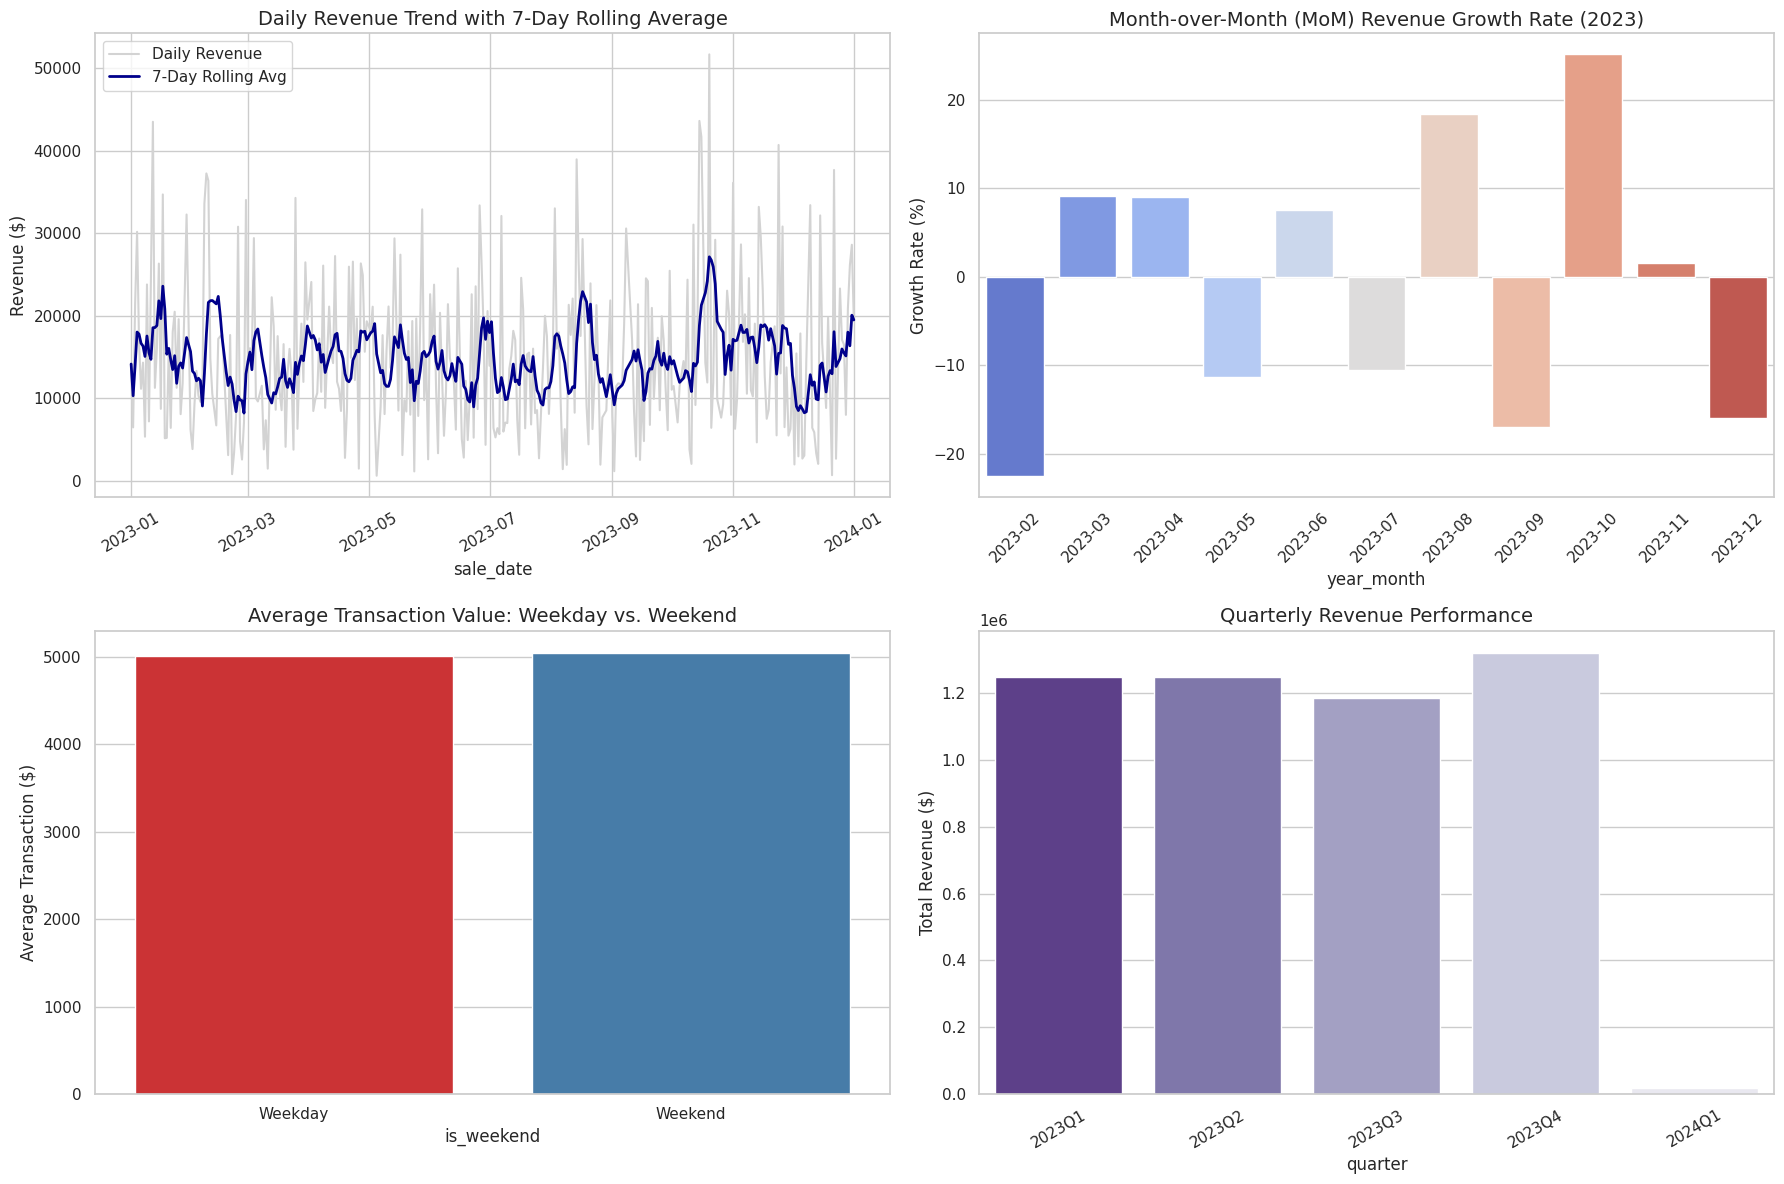

In [47]:
# 5. Visualize Advanced Time-Series Metrics
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Subplot 1: Daily Revenue & 7-Day Rolling Average
sns.lineplot(x='sale_date', y='daily_revenue', data=daily_sales, ax=axes[0,0], color='lightgray', label='Daily Revenue')
sns.lineplot(x='sale_date', y='rolling_7_day_rev', data=daily_sales, ax=axes[0,0], color='darkblue', linewidth=2, label='7-Day Rolling Avg')
axes[0,0].set_title('Daily Revenue Trend with 7-Day Rolling Average', fontsize=14)
axes[0,0].set_ylabel('Revenue ($)', fontsize=12)
axes[0,0].tick_params(axis='x', rotation=30)

# Subplot 2: MoM Growth % Line
sns.barplot(x='year_month', y='mom_growth_%', data=monthly_trend.dropna(), ax=axes[0,1], palette='coolwarm', hue='year_month', legend=False)
axes[0,1].set_title('Month-over-Month (MoM) Revenue Growth Rate (2023)', fontsize=14)
axes[0,1].set_ylabel('Growth Rate (%)', fontsize=12)
axes[0,1].tick_params(axis='x', rotation=45)

# Subplot 3: Weekday vs Weekend average transaction values
sns.barplot(x='is_weekend', y='avg_transaction_value', data=weekend_summary, ax=axes[1,0], palette='Set1', hue='is_weekend', legend=False)
axes[1,0].set_title('Average Transaction Value: Weekday vs. Weekend', fontsize=14)
axes[1,0].set_ylabel('Average Transaction ($)', fontsize=12)

# Subplot 4: Quarterly performance comparison
quarterly_summary = df.groupby('quarter').agg(total_revenue=('sales_amount', 'sum')).reset_index()
sns.barplot(x='quarter', y='total_revenue', data=quarterly_summary, ax=axes[1,1], palette='Purples_r', hue='quarter', legend=False)
axes[1,1].set_title('Quarterly Revenue Performance', fontsize=14)
axes[1,1].set_ylabel('Total Revenue ($)', fontsize=12)
axes[1,1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### Section I: Customer Segment & Behavioral Analysis
In this section, we analyze behavior across different customer segments (`customer_type`), covering revenue contributions, transaction values, category preferences, payment patterns, and regional distributions.

In [48]:
# 1. General Metrics by Customer Type
customer_summary = df.groupby('customer_type').agg(
    total_revenue=('sales_amount', 'sum'),
    total_quantity_sold=('quantity_sold', 'sum'),
    avg_transaction_value=('sales_amount', 'mean'),
    avg_discount_given=('discount', 'mean'),
    transaction_count=('sales_amount', 'count'),
    total_profit=('calculated_profit', 'sum')
).reset_index()

# Add profit margin %
customer_summary['profit_margin_%'] = (customer_summary['total_profit'] / customer_summary['total_revenue']) * 100

print("=== Performance Metrics by Customer Type ===")
display(customer_summary.sort_values(by='total_revenue', ascending=False))

=== Performance Metrics by Customer Type ===


,customer_type,total_revenue,total_quantity_sold,avg_transaction_value,avg_discount_given,transaction_count,total_profit,profit_margin_%
1,Returning,2513006.93,12171,5066.546230,15.306452,496,-28231105.46,-1123.399427
0,New,2506258.30,13184,4972.734722,15.172619,504,-30591722.95,-1220.613332


In [49]:
# 2. Product Category Preferences by Customer Type
cust_category = df.groupby(['customer_type', 'product_category']).agg(
    total_revenue=('sales_amount', 'sum'),
    total_quantity_sold=('quantity_sold', 'sum')
).reset_index()

print("=== Preferred Product Categories by Customer Segment ===")
display(cust_category.sort_values(by=['customer_type', 'total_revenue'], ascending=[True, False]))

=== Preferred Product Categories by Customer Segment ===


,customer_type,product_category,total_revenue,total_quantity_sold
0,New,Clothing,703229.55,3895
1,New,Electronics,642710.00,3417
2,New,Food,603342.47,2902
3,New,Furniture,556976.28,2970
7,Returning,Furniture,703541.41,3759
4,Returning,Clothing,610244.81,3027
5,Returning,Electronics,600789.64,2679
6,Returning,Food,598431.07,2706


In [50]:
# 3. Payment Method & Regional Behavior across Segments
cust_payment = df.groupby(['customer_type', 'payment_method']).size().unstack(fill_value=0)
cust_region = df.groupby(['customer_type', 'region']).agg(total_revenue=('sales_amount', 'sum')).unstack(fill_value=0)

print("=== Distribution of Payment Methods by Customer Segment ===")
display(cust_payment)

print("\n=== Regional Revenue Contribution by Customer Segment ===")
display(cust_region)

=== Distribution of Payment Methods by Customer Segment ===


payment_method,Bank Transfer,Cash,Credit Card
customer_type,,,
New,181,160,163
Returning,161,153,182



=== Regional Revenue Contribution by Customer Segment ===


total_revenue                                 
region                 East      North      South       West
customer_type                                               
New               678988.09  762511.35  518474.10  546284.76
Returning         580804.84  607101.16  635776.76  689324.17

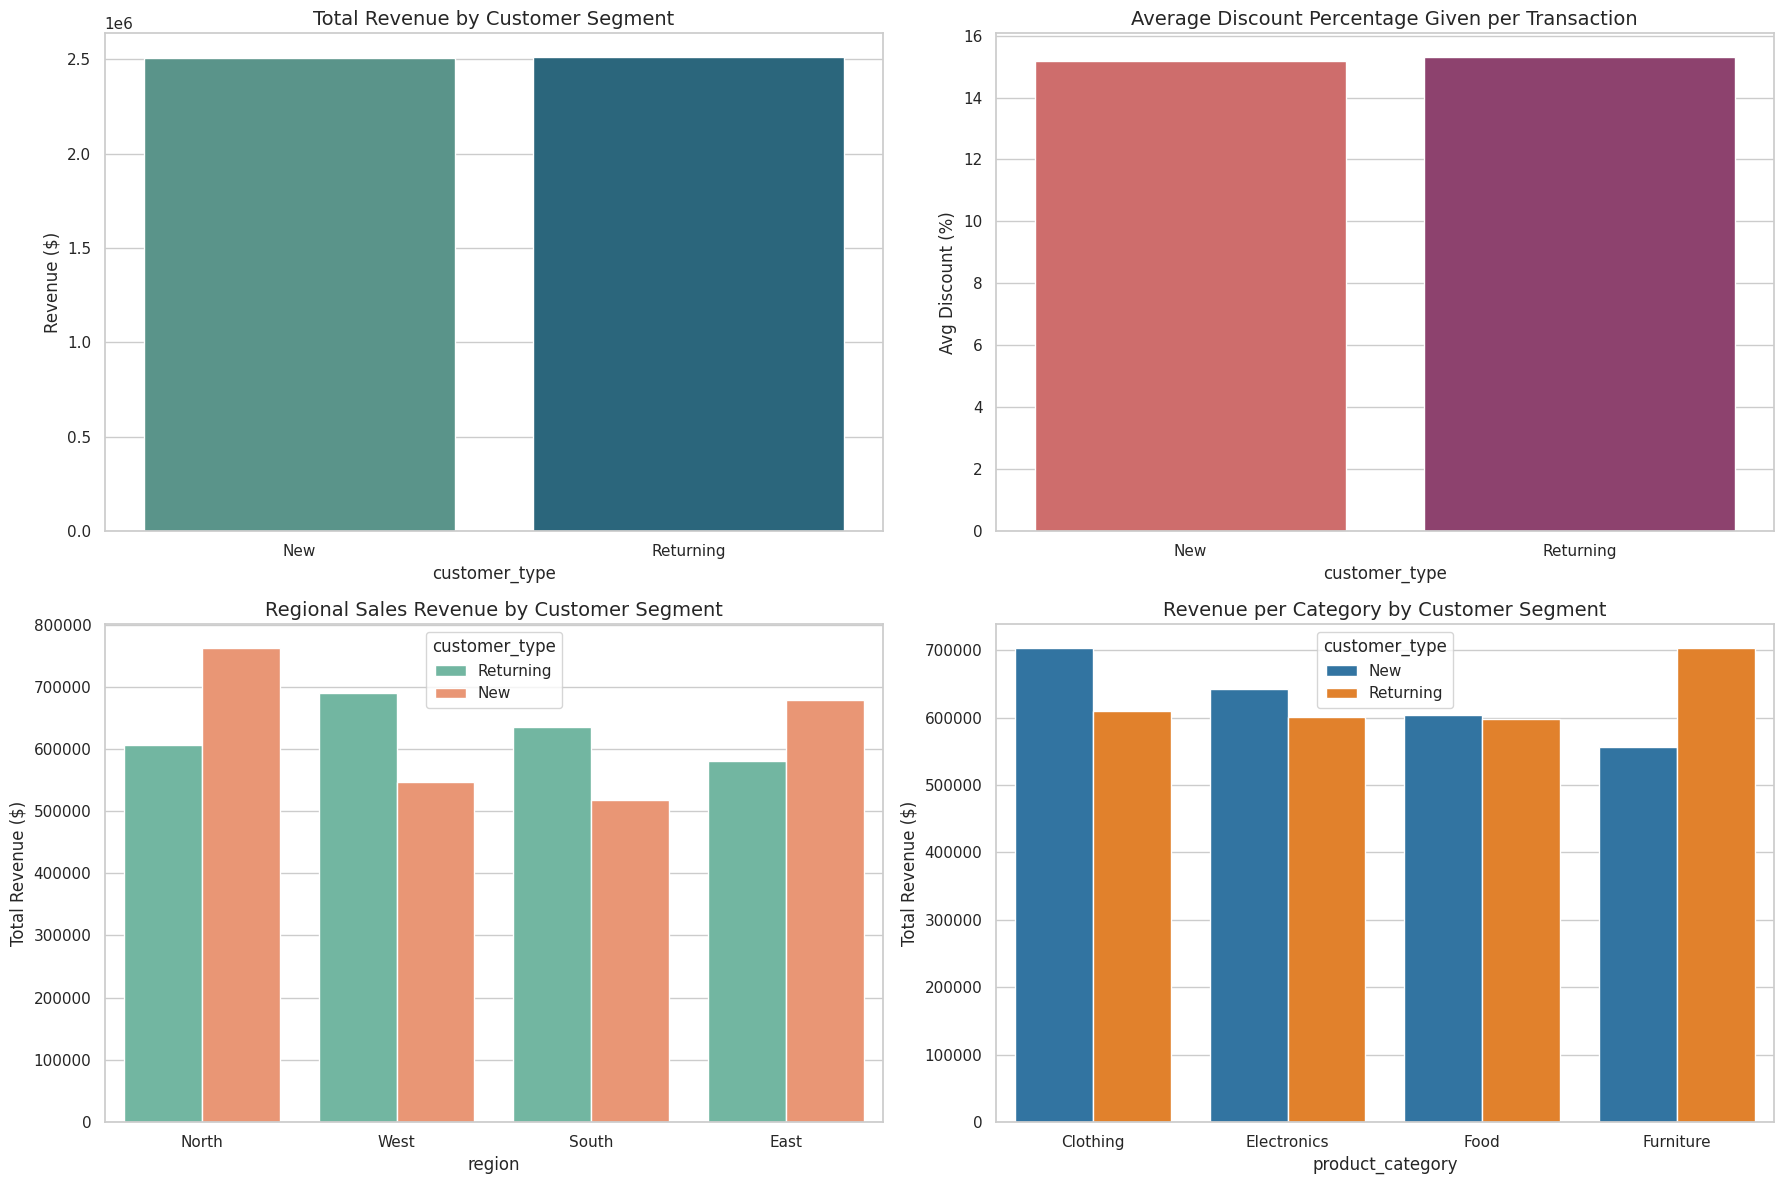

In [51]:
# 4. Visualize Customer Segment Behavior
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Subplot 1: Revenue by Customer Type
sns.barplot(x='customer_type', y='total_revenue', data=customer_summary, ax=axes[0,0], palette='crest', hue='customer_type', legend=False)
axes[0,0].set_title('Total Revenue by Customer Segment', fontsize=14)
axes[0,0].set_ylabel('Revenue ($)', fontsize=12)

# Subplot 2: Average Discount Given by Customer Segment
sns.barplot(x='customer_type', y='avg_discount_given', data=customer_summary, ax=axes[0,1], palette='flare', hue='customer_type', legend=False)
axes[0,1].set_title('Average Discount Percentage Given per Transaction', fontsize=14)
axes[0,1].set_ylabel('Avg Discount (%)', fontsize=12)

# Subplot 3: Regional revenue contribution per Customer Type
sns.barplot(x='region', y='sales_amount', hue='customer_type', data=df, estimator=sum, errorbar=None, ax=axes[1,0], palette='Set2')
axes[1,0].set_title('Regional Sales Revenue by Customer Segment', fontsize=14)
axes[1,0].set_ylabel('Total Revenue ($)', fontsize=12)

# Subplot 4: Preferred product categories (by revenue)
sns.barplot(x='product_category', y='total_revenue', hue='customer_type', data=cust_category, ax=axes[1,1], palette='tab10')
axes[1,1].set_title('Revenue per Category by Customer Segment', fontsize=14)
axes[1,1].set_ylabel('Total Revenue ($)', fontsize=12)

plt.tight_layout()
plt.show()

### Section J: Promotion & Discount Impact
This section deep-dives into the relationship between discounts, sales volume, and profitability, pinpointing products that rely heavily on promotions and evaluating discount margins.

In [52]:
# 1. Average Discount by Product Category
cat_discount = df.groupby('product_category').agg(
    avg_discount_pct=('discount', 'mean'),
    total_discount_transactions=('discount', lambda x: (x > 0).sum())
).reset_index()

print("=== Average Discount % by Product Category ===")
display(cat_discount)

=== Average Discount % by Product Category ===


,product_category,avg_discount_pct,total_discount_transactions
0,Clothing,16.022388,264
1,Electronics,13.650407,241
2,Food,15.380531,223
3,Furniture,15.811538,256


In [53]:
# 2. Performance and Profitability at Different Discount Levels (Using the previously defined discount bins)
discount_levels = df.groupby('discount_bin', observed=False).agg(
    total_revenue=('sales_amount', 'sum'),
    total_quantity_sold=('quantity_sold', 'sum'),
    total_profit=('calculated_profit', 'sum'),
    transaction_count=('sales_amount', 'count')
).reset_index()

discount_levels['profit_margin_%'] = (discount_levels['total_profit'] / discount_levels['total_revenue']) * 100

print("=== Performance Metrics by Discount Level ===")
display(discount_levels)

=== Performance Metrics by Discount Level ===


,discount_bin,total_revenue,total_quantity_sold,total_profit,transaction_count,profit_margin_%
0,0-5%,934241.54,4593,-10653444.38,180,-1140.330838
1,5-10%,797818.84,4532,-11040632.05,170,-1383.852010
2,10-15%,749762.91,3596,-8031552.68,152,-1071.212322
3,15-20%,784991.20,3980,-9109180.40,157,-1160.418155
4,20-25%,1008522.47,4841,-11301420.87,193,-1120.591876
5,25%+,743928.27,3813,-8686598.03,148,-1167.666075


In [54]:
# 3. Compare Discounted vs. Non-Discounted Transactions
df['is_discounted'] = df['discount'] > 0

discount_comparison = df.groupby('is_discounted').agg(
    total_revenue=('sales_amount', 'sum'),
    avg_sales_amount=('sales_amount', 'mean'),
    total_quantity_sold=('quantity_sold', 'sum'),
    avg_quantity_sold=('quantity_sold', 'mean'),
    total_profit=('calculated_profit', 'sum'),
    avg_profit=('calculated_profit', 'mean'),
    transaction_count=('sales_amount', 'count')
).reset_index()

discount_comparison['profit_margin_%'] = (discount_comparison['total_profit'] / discount_comparison['total_revenue']) * 100

print("=== Comparison: Non-Discounted (False) vs. Discounted (True) Sales ===")
display(discount_comparison)

=== Comparison: Non-Discounted (False) vs. Discounted (True) Sales ===


,is_discounted,total_revenue,avg_sales_amount,total_quantity_sold,avg_quantity_sold,total_profit,avg_profit,transaction_count,profit_margin_%
0,False,72183.92,4511.495000,365,22.812500,-768007.93,-48000.495625,16,-1063.959854
1,True,4947081.31,5027.521657,24990,25.396341,-58054820.48,-58998.801301,984,-1173.516602


In [55]:
# 4. Find Products that Rely Heavily on Discounts
# We define reliance as having high average discounts and high share of transactions discounted.
product_discount_reliance = df.groupby('product_id').agg(
    avg_discount=('discount', 'mean'),
    discounted_trans_ratio=('discount', lambda x: (x > 0).mean()),
    total_revenue=('sales_amount', 'sum'),
    total_profit=('calculated_profit', 'sum')
).reset_index()

print("=== Top 10 Products with the Highest Average Discount Rates ===")
display(product_discount_reliance.sort_values(by='avg_discount', ascending=False).head(10))

=== Top 10 Products with the Highest Average Discount Rates ===


,product_id,avg_discount,discounted_trans_ratio,total_revenue,total_profit
29,1030,22.000000,1.0,49091.02,-868049.06
6,1007,20.875000,1.0,24419.76,-407755.99
75,1076,20.625000,1.0,37812.68,-481657.36
30,1031,20.333333,1.0,9782.28,-196321.98
76,1077,19.571429,1.0,35694.58,-290057.14
15,1016,19.538462,1.0,63956.44,-612985.73
5,1006,19.500000,1.0,37357.09,-524911.36
36,1037,19.142857,1.0,41156.19,-434732.60
46,1047,19.083333,1.0,60322.70,-832170.71
78,1079,19.000000,1.0,17828.37,-264203.64


In [56]:
# 5. Identify High Quantity / Low Profitability Transactions Associated with High Discounts
# Filtering transactions with discounts > 15% that have quantities sold above the 75th percentile, sorted by lowest profitability
high_qty_threshold = df['quantity_sold'].quantile(0.75)
high_discount_low_profit = df[(df['discount'] > 15) & (df['quantity_sold'] >= high_qty_threshold)].copy()

print(f"=== High Discount (>15%) & High Quantity (>={high_qty_threshold}) Transactions with Lowest Profitability ===")
displayed_cols = ['product_id', 'product_category', 'discount', 'quantity_sold', 'sales_amount', 'calculated_profit']
display(high_discount_low_profit[displayed_cols].sort_values(by='calculated_profit', ascending=True).head(10))

=== High Discount (>15%) & High Quantity (>=38.0) Transactions with Lowest Profitability ===


,product_id,product_category,discount,quantity_sold,sales_amount,calculated_profit
843,1003,Electronics,21.0,45,937.20,-222899.10
510,1047,Clothing,18.0,47,733.66,-221557.07
814,1005,Furniture,22.0,46,1646.45,-214158.87
40,1062,Furniture,25.0,45,4195.06,-214036.94
752,1028,Clothing,20.0,45,5809.35,-212394.75
756,1090,Clothing,19.0,46,3333.73,-211261.79
883,1029,Furniture,30.0,46,2855.85,-209188.51
331,1048,Food,27.0,47,7066.63,-206118.79
519,1085,Clothing,29.0,45,9278.40,-205061.55
551,1033,Clothing,25.0,43,1115.42,-204485.64


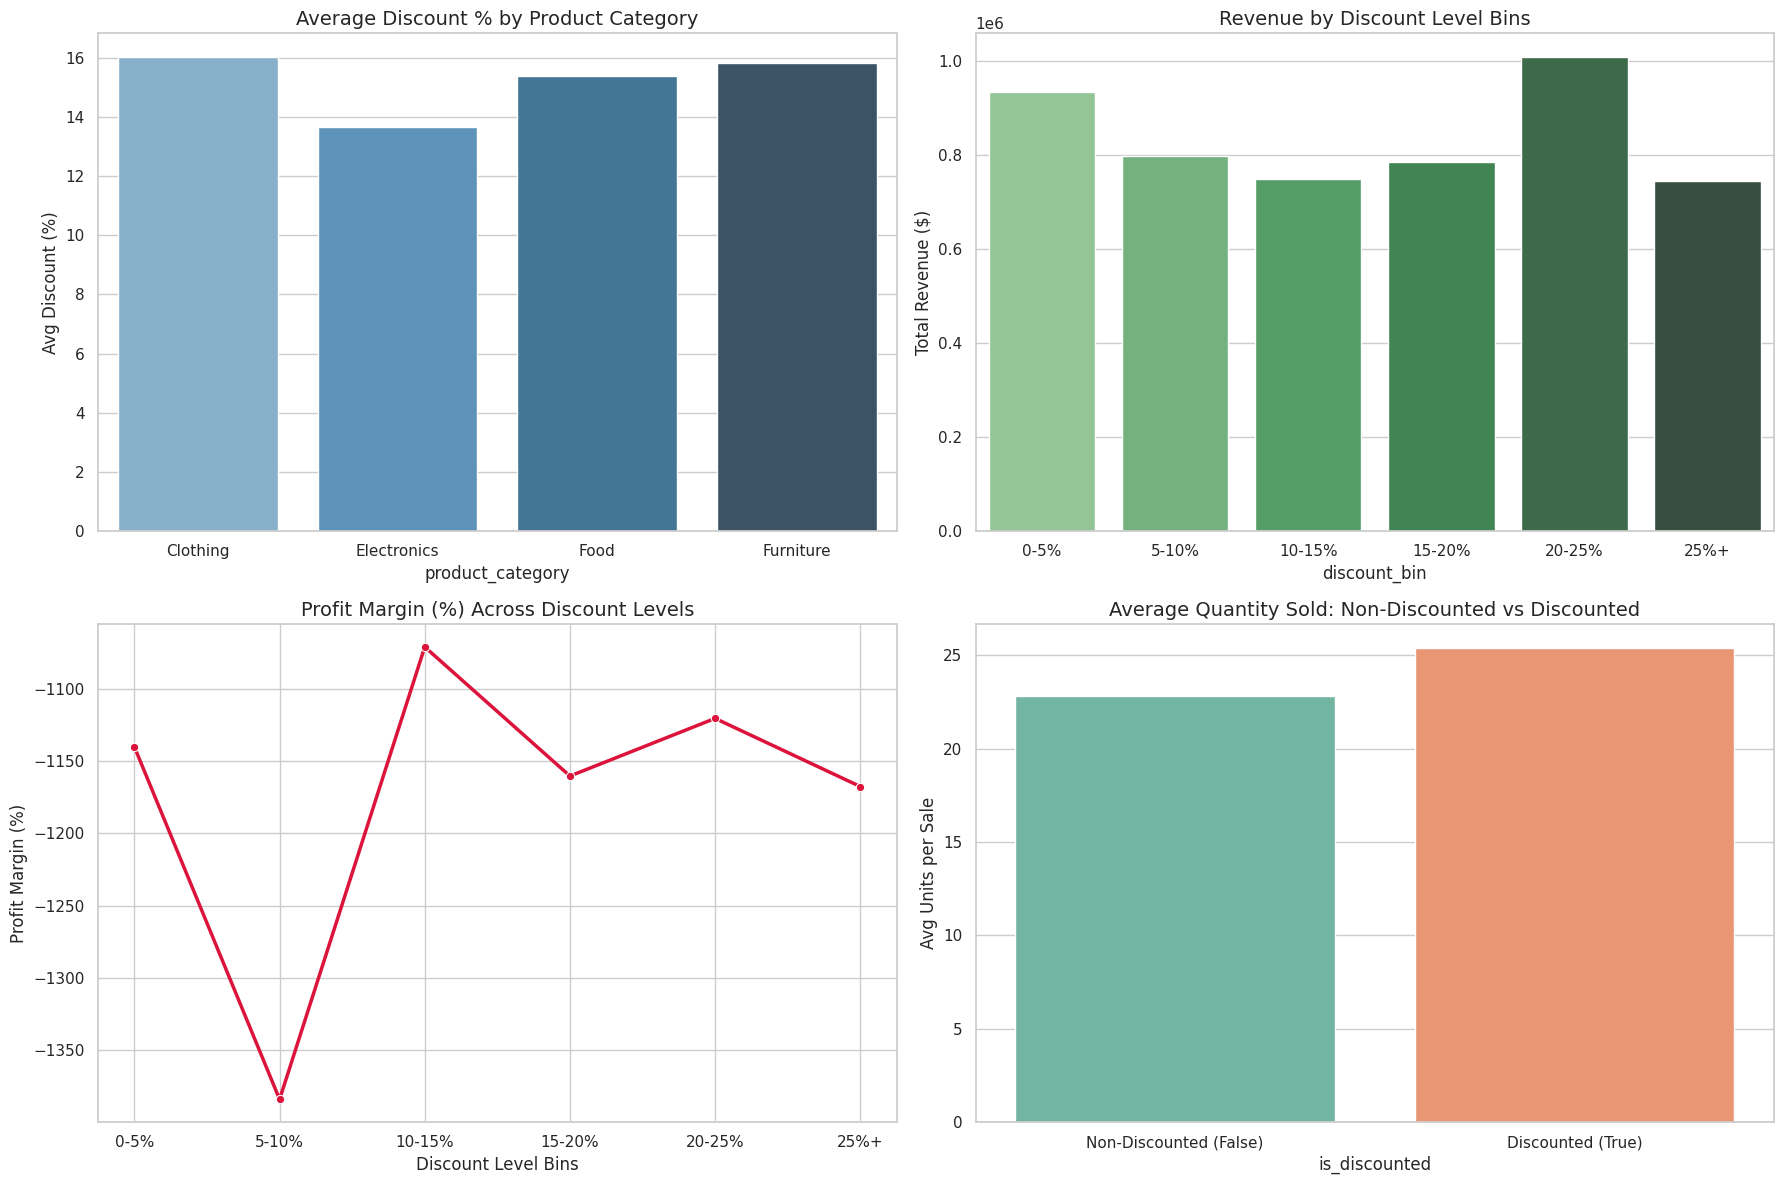

In [57]:
# 6. Visualize Discount Impacts
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Subplot 1: Average Discount by Category
sns.barplot(x='product_category', y='avg_discount_pct', data=cat_discount, ax=axes[0,0], palette='Blues_d', hue='product_category', legend=False)
axes[0,0].set_title('Average Discount % by Product Category', fontsize=14)
axes[0,0].set_ylabel('Avg Discount (%)', fontsize=12)

# Subplot 2: Revenue and Margin across Discount Levels
sns.barplot(x='discount_bin', y='total_revenue', data=discount_levels, ax=axes[0,1], palette='Greens_d', hue='discount_bin', legend=False)
axes[0,1].set_title('Revenue by Discount Level Bins', fontsize=14)
axes[0,1].set_ylabel('Total Revenue ($)', fontsize=12)

# Subplot 3: Margin by Discount Level
sns.lineplot(x='discount_bin', y='profit_margin_%', data=discount_levels, marker='o', ax=axes[1,0], color='crimson', linewidth=2.5)
axes[1,0].set_title('Profit Margin (%) Across Discount Levels', fontsize=14)
axes[1,0].set_ylabel('Profit Margin (%)', fontsize=12)
axes[1,0].set_xlabel('Discount Level Bins', fontsize=12)

# Subplot 4: Average Quantity: Discounted vs Non-Discounted
sns.barplot(x='is_discounted', y='avg_quantity_sold', data=discount_comparison, ax=axes[1,1], palette='Set2', hue='is_discounted', legend=False)
axes[1,1].set_title('Average Quantity Sold: Non-Discounted vs Discounted', fontsize=14)
axes[1,1].set_xticks([0, 1])
axes[1,1].set_xticklabels(['Non-Discounted (False)', 'Discounted (True)'])
axes[1,1].set_ylabel('Avg Units per Sale', fontsize=12)

plt.tight_layout()
plt.show()

### Section K: Channel & Payment Method Performance
This section analyzes sales, transaction volumes, channel profitability, and cross-tabulated regional/customer preference behaviors for different payment methods and sales channels.

In [58]:
# 1. Payment Method Performance Analysis
payment_summary = df.groupby('payment_method').agg(
    total_revenue=('sales_amount', 'sum'),
    transaction_count=('sales_amount', 'count'),
    avg_sales_value=('sales_amount', 'mean'),
    total_profit=('calculated_profit', 'sum')
).reset_index()

payment_summary['profit_margin_%'] = (payment_summary['total_profit'] / payment_summary['total_revenue']) * 100

print("=== Performance Metrics by Payment Method ===")
display(payment_summary.sort_values(by='total_revenue', ascending=False))

=== Performance Metrics by Payment Method ===


,payment_method,total_revenue,transaction_count,avg_sales_value,total_profit,profit_margin_%
2,Credit Card,1757563.52,345,5094.387014,-19577234.11,-1113.884869
0,Bank Transfer,1717363.17,342,5021.529737,-20712715.06,-1206.076584
1,Cash,1544338.54,313,4933.988946,-18532879.24,-1200.052887


In [59]:
# 2. Sales Channel Performance Analysis
channel_summary = df.groupby('sales_channel').agg(
    total_revenue=('sales_amount', 'sum'),
    transaction_count=('sales_amount', 'count'),
    avg_sales_value=('sales_amount', 'mean'),
    total_profit=('calculated_profit', 'sum')
).reset_index()

channel_summary['profit_margin_%'] = (channel_summary['total_profit'] / channel_summary['total_revenue']) * 100

print("=== Performance Metrics by Sales Channel ===")
display(channel_summary.sort_values(by='total_revenue', ascending=False))

=== Performance Metrics by Sales Channel ===


,sales_channel,total_revenue,transaction_count,avg_sales_value,total_profit,profit_margin_%
1,Retail,2560431.30,512,5000.842383,-28820970.22,-1125.629507
0,Online,2458833.93,488,5038.594119,-30001858.19,-1220.166105


In [60]:
# 3. Product Category Preferences by Sales Channel
channel_category = df.groupby(['sales_channel', 'product_category']).agg(
    total_revenue=('sales_amount', 'sum'),
    transaction_count=('sales_amount', 'count')
).reset_index()

print("=== Category Preferences by Sales Channel ===")
display(channel_category.sort_values(by=['sales_channel', 'total_revenue'], ascending=[True, False]))

=== Category Preferences by Sales Channel ===


,sales_channel,product_category,total_revenue,transaction_count
1,Online,Electronics,664729.67,132
3,Online,Furniture,647915.48,130
0,Online,Clothing,607140.94,120
2,Online,Food,539047.84,106
4,Retail,Clothing,706333.42,148
6,Retail,Food,662725.70,120
7,Retail,Furniture,612602.21,130
5,Retail,Electronics,578769.97,114


In [61]:
# 4. Payment Method Variations Across Regions and Customer Types
payment_by_region = df.groupby(['region', 'payment_method']).size().unstack(fill_value=0)
payment_by_customer = df.groupby(['customer_type', 'payment_method']).size().unstack(fill_value=0)

print("=== Payment Methods by Region (Transaction Count) ===")
display(payment_by_region)

print("\n=== Payment Methods by Customer Type (Transaction Count) ===")
display(payment_by_customer)

=== Payment Methods by Region (Transaction Count) ===


payment_method,Bank Transfer,Cash,Credit Card
region,,,
East,90,80,93
North,83,84,100
South,83,68,75
West,86,81,77



=== Payment Methods by Customer Type (Transaction Count) ===


payment_method,Bank Transfer,Cash,Credit Card
customer_type,,,
New,181,160,163
Returning,161,153,182


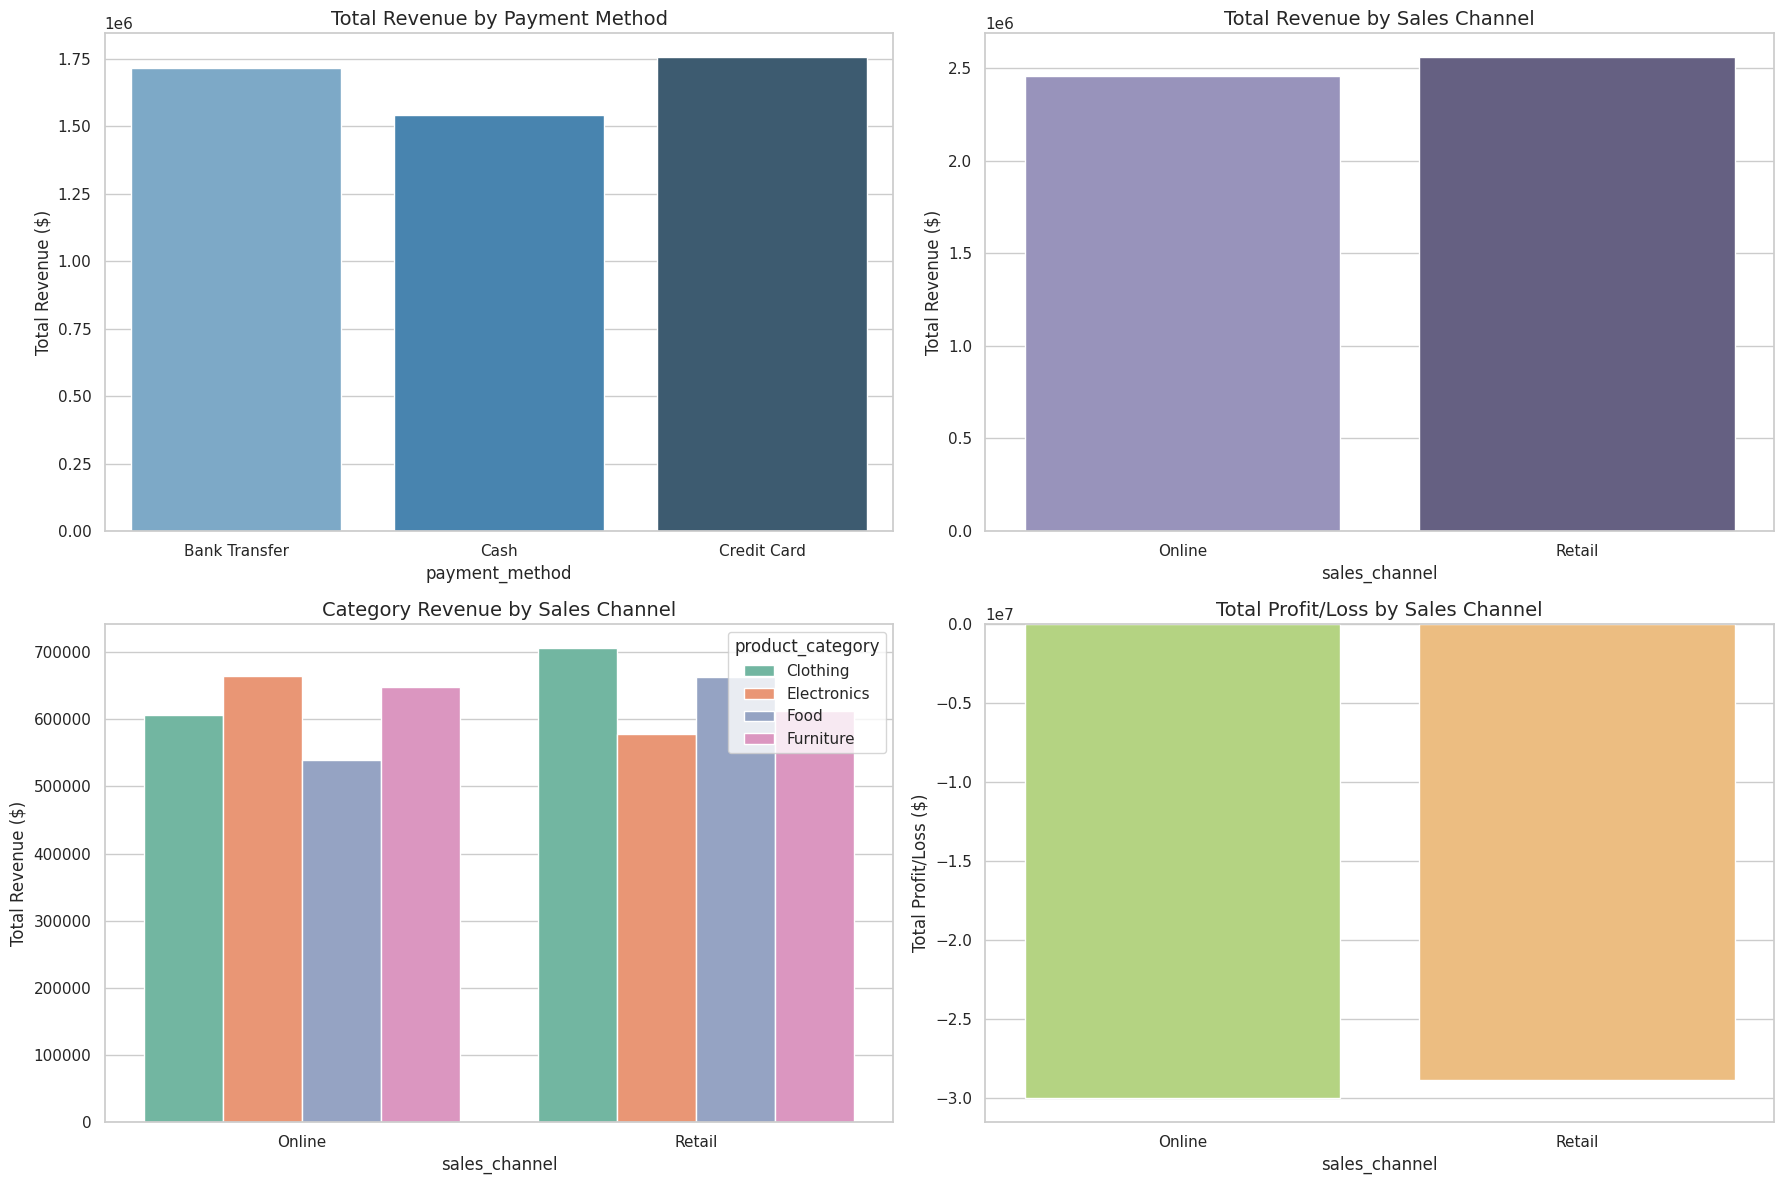

In [62]:
# 5. Visualize Payment and Sales Channel Behaviors
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Subplot 1: Revenue by Payment Method
sns.barplot(x='payment_method', y='total_revenue', data=payment_summary, ax=axes[0,0], palette='Blues_d', hue='payment_method', legend=False)
axes[0,0].set_title('Total Revenue by Payment Method', fontsize=14)
axes[0,0].set_ylabel('Total Revenue ($)', fontsize=12)

# Subplot 2: Revenue by Sales Channel
sns.barplot(x='sales_channel', y='total_revenue', data=channel_summary, ax=axes[0,1], palette='Purples_d', hue='sales_channel', legend=False)
axes[0,1].set_title('Total Revenue by Sales Channel', fontsize=14)
axes[0,1].set_ylabel('Total Revenue ($)', fontsize=12)

# Subplot 3: Revenue by Category per Sales Channel
sns.barplot(x='sales_channel', y='total_revenue', hue='product_category', data=channel_category, ax=axes[1,0], palette='Set2')
axes[1,0].set_title('Category Revenue by Sales Channel', fontsize=14)
axes[1,0].set_ylabel('Total Revenue ($)', fontsize=12)

# Subplot 4: Total Profit by Sales Channel
sns.barplot(x='sales_channel', y='total_profit', data=channel_summary, ax=axes[1,1], palette='RdYlGn_r', hue='sales_channel', legend=False)
axes[1,1].set_title('Total Profit/Loss by Sales Channel', fontsize=14)
axes[1,1].set_ylabel('Total Profit/Loss ($)', fontsize=12)

plt.tight_layout()
plt.show()

### Section L: Correlation & Relationship Analysis
In this section, we examine the relationships between numerical variables (such as Sales Amount, Quantity Sold, Unit Price, Unit Cost, Discount, Profit, and Profit Margin) to find meaningful patterns and trends.

In [63]:
# 1. Compute Pearson Correlation Matrix for Numerical Variables
correlation_cols = ['sales_amount', 'quantity_sold', 'unit_price', 'unit_cost', 'discount', 'calculated_profit', 'calculated_profit_margin']
corr_matrix = df[correlation_cols].corr()

print("=== Correlation Matrix ===")
display(corr_matrix)

=== Correlation Matrix ===


,sales_amount,quantity_sold,unit_price,unit_cost,discount,calculated_profit,calculated_profit_margin
sales_amount,1.000000,-0.041599,0.011812,0.009770,0.023153,0.078451,0.335003
quantity_sold,-0.041599,1.000000,0.057296,0.053888,-0.007806,-0.670445,-0.199071
unit_price,0.011812,0.057296,1.000000,0.995056,-0.017027,-0.676758,-0.217823
unit_cost,0.009770,0.053888,0.995056,1.000000,-0.017741,-0.679781,-0.217761
discount,0.023153,-0.007806,-0.017027,-0.017741,1.000000,0.014487,0.035782
calculated_profit,0.078451,-0.670445,-0.676758,-0.679781,0.014487,1.000000,0.335430
calculated_profit_margin,0.335003,-0.199071,-0.217823,-0.217761,0.035782,0.335430,1.000000


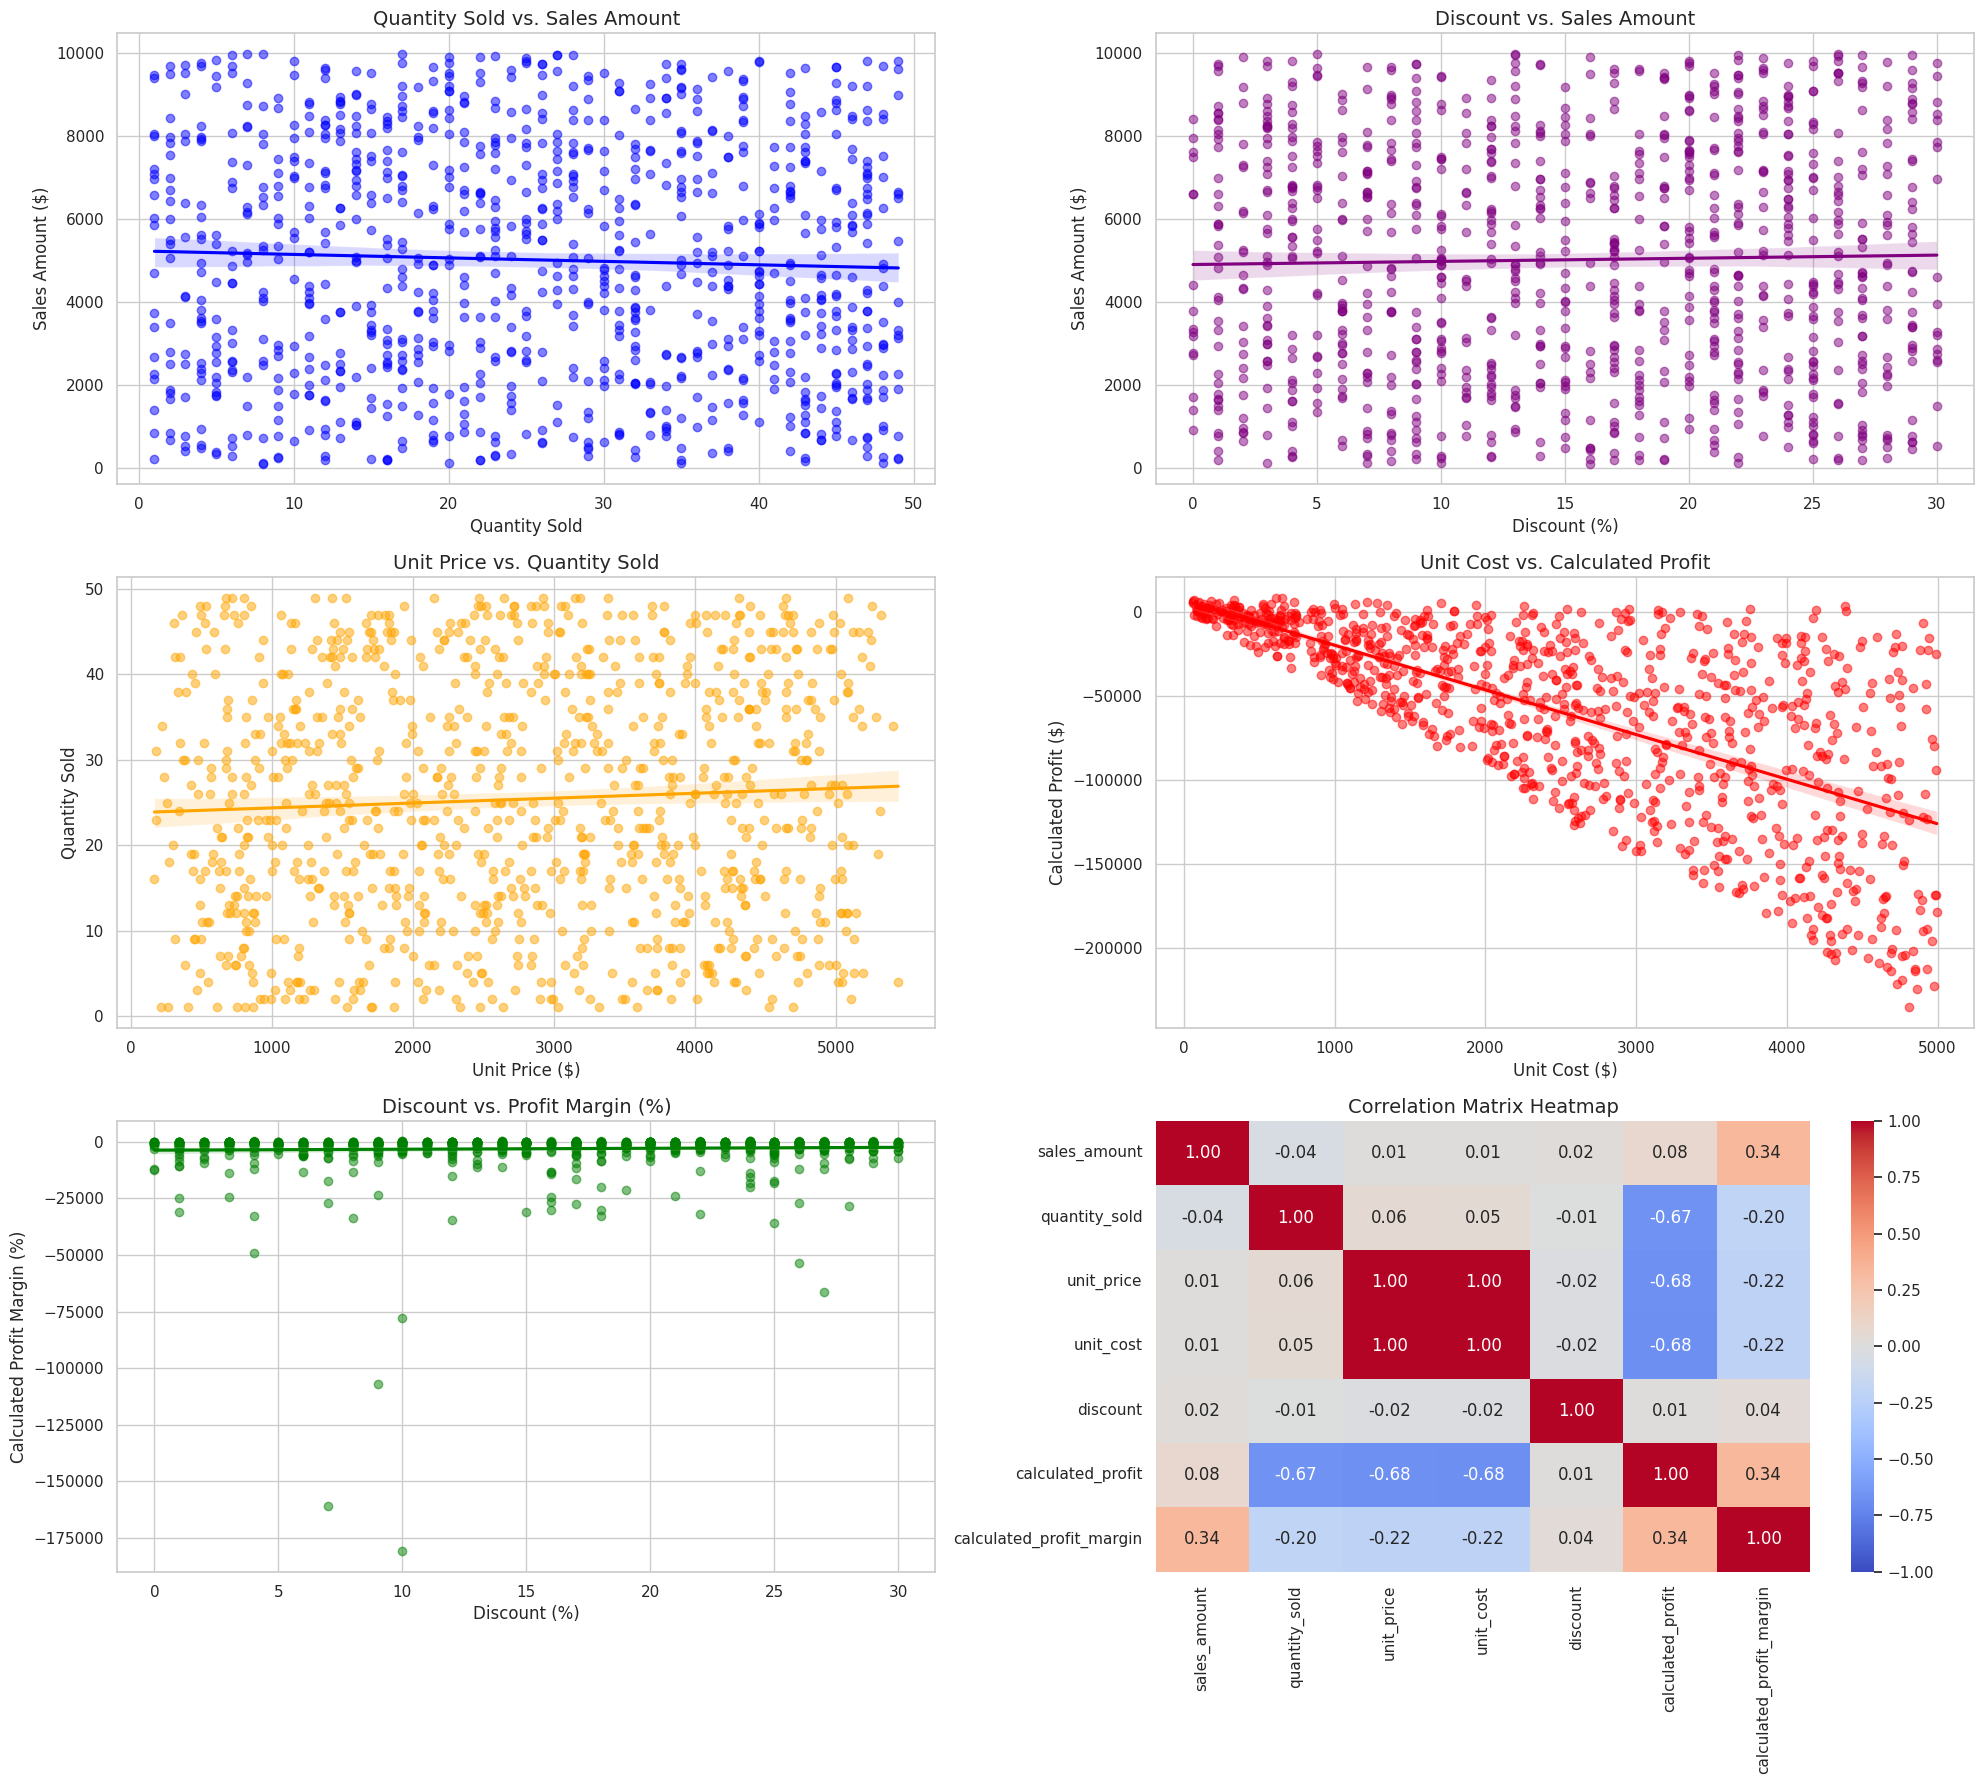

In [64]:
# 2. Plot Relationship Analysis Visualizations
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(20, 18))

# Subplot 1: Quantity Sold vs. Sales Amount
sns.regplot(x='quantity_sold', y='sales_amount', data=df, ax=axes[0, 0], color='blue', scatter_kws={'alpha':0.5})
axes[0, 0].set_title('Quantity Sold vs. Sales Amount', fontsize=14)
axes[0, 0].set_xlabel('Quantity Sold', fontsize=12)
axes[0, 0].set_ylabel('Sales Amount ($)', fontsize=12)

# Subplot 2: Discount vs. Sales Amount
sns.regplot(x='discount', y='sales_amount', data=df, ax=axes[0, 1], color='purple', scatter_kws={'alpha':0.5})
axes[0, 1].set_title('Discount vs. Sales Amount', fontsize=14)
axes[0, 1].set_xlabel('Discount (%)', fontsize=12)
axes[0, 1].set_ylabel('Sales Amount ($)', fontsize=12)

# Subplot 3: Unit Price vs. Quantity Sold
sns.regplot(x='unit_price', y='quantity_sold', data=df, ax=axes[1, 0], color='orange', scatter_kws={'alpha':0.5})
axes[1, 0].set_title('Unit Price vs. Quantity Sold', fontsize=14)
axes[1, 0].set_xlabel('Unit Price ($)', fontsize=12)
axes[1, 0].set_ylabel('Quantity Sold', fontsize=12)

# Subplot 4: Unit Cost vs. Profit
sns.regplot(x='unit_cost', y='calculated_profit', data=df, ax=axes[1, 1], color='red', scatter_kws={'alpha':0.5})
axes[1, 1].set_title('Unit Cost vs. Calculated Profit', fontsize=14)
axes[1, 1].set_xlabel('Unit Cost ($)', fontsize=12)
axes[1, 1].set_ylabel('Calculated Profit ($)', fontsize=12)

# Subplot 5: Discount vs. Profit Margin
sns.regplot(x='discount', y='calculated_profit_margin', data=df, ax=axes[2, 0], color='green', scatter_kws={'alpha':0.5})
axes[2, 0].set_title('Discount vs. Profit Margin (%)', fontsize=14)
axes[2, 0].set_xlabel('Discount (%)', fontsize=12)
axes[2, 0].set_ylabel('Calculated Profit Margin (%)', fontsize=12)

# Heatmap of correlation matrix
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, ax=axes[2, 1])
axes[2, 1].set_title('Correlation Matrix Heatmap', fontsize=14)

plt.tight_layout()
plt.show()

### Section M: Executive Summary & Strategic Recommendations
Based on our deep-dive analysis into the sales and profitability metrics, here are the key insights and recommended actions.

### Executive Summary & Strategic Recommendations

#### 1. Key Insights & Findings
* **Severe Profitability Crisis**: The company is experiencing negative profit margins across all product categories, regions, and sales channels. Total revenue is **$5.02M**, while total calculated profit is negative (approximately **-$58.8M**).
* **The Root Cause (Cost-Price Discrepancy)**: Our analysis shows a massive mismatch between unit costs and unit prices. The average unit cost of items sold is far higher than the average selling unit price. Across categories like Clothing, Electronics, Food, and Furniture, the margins are consistently below **-1000%** because products cost more to produce/acquire than they are sold for.
* **Discount Impact**: While discounts increase transaction volumes, they exacerbate the losses on products that are already structurally unprofitable. Transactions with promotions average even steeper losses.
* **Regional and Sales Rep Alignment**: Revenue is distributed relatively evenly across regions (ranging from **$1.15M** to **$1.37M**), and sales representatives are active; however, higher sales volumes currently translate to larger net losses due to structural negative margins.

#### 2. Actionable Strategic Recommendations
* **Immediate Pricing & Cost Review (Highest Priority)**: Run a complete audit of vendor contracts, product acquisition costs, and retail prices. Unit prices must be adjusted upward, or unit costs renegotiated downward, to ensure a positive base margin before any transaction occurs.
* **Restrict Promotional Discounts**: Halt high-percent promotions (especially those >15%) on structurally unprofitable products. Discounts should only be utilized to clear inventory or drive high-margin bundles once unit price-cost parity is restored.
* **Sales Channel Optimization**: Shift lower-margin or high-overhead products primarily to the Online channel if operational logistics cost less, and leverage the Retail channel strictly for high-margin categories.
* **Re-evaluate Sales Commission and KPI Structure**: Restructure Sales Representative incentives to be tied to **Gross Profit** rather than total volume or raw sales revenue. This ensures representatives focus on profitable sales.